# ステージ5-B: 株ごと独立 DESeq2（eptA oligo metatranscriptome）

`5_1_DESeq2_A_community.ipynb`（(A) 全株プール）の続き。**(B) 株ごと独立 DESeq2** を実施する。

## (A) と (B) の違いは size factor の範囲だけ

```
(A)  ライブラリ全体（9,795 遺伝子）で size factor を1組   → 株のシェア変化を含む
(B)  株ごとに size factor を1組ずつ（計4組）              → 株のシェア変化が消える
```

**それ以外（入力・フィルタ・検定・収縮）は (A) とまったく同じ。**
**同じ 9,795 遺伝子**を使うので、1遺伝子ずつ1対1で比較できる。

| 観点 | **(A) 全株プール** | **(B) 株ごと独立**（このnotebook） |
|---|---|---|
| **目的** | 菌叢の遺伝子発現から**宿主への作用**を考察する | **各菌の内部制御**を知る |
| 問い | 宿主は何にさらされているか | 各菌が自分の中で何を上げ下げしたか |
| 菌の増減による転写産物量の変化 | **含む（＝測りたいもの）** | **含まない** |

**主従はつけない**（CLAUDE.md §7 ステージ5）。
**最も情報量が多いのは「片方でのみ有意」な経路**で、最終成果物はこの2つを左右に並べた図。

## ★ 過去プロジェクトに前例が無い

`230313_T19_33mix` と `240704_T19_28strains` の**全notebook を確認した結果、
DESeq2 は1回だけ＝プール解析のみ**で、**株ごとの解析は実施されていなかった**
（`DESeqDataSetFromMatrix` が各1回、株ごとループの痕跡は0）。

**(B) は今回が初回。** したがって多重検定の範囲をどう取るかは**今回決める。**
**両方を列として持つ**（セル5）。

| 列 | 中身 | 使いどころ |
|---|---|---|
| `padj_bystrain` | DESeq2 が株ごとに付けた padj（株内で BH） | **その株だけを見るとき** |
| `padj_pooled` | 4株の生 p 値をまとめて BH を1回 | **(A) との比較**（同じ土俵） |

## このnotebook の流れ

| セル | 内容 |
|---|---|
| 1–3 | ライブラリ / パス / **(A) が保存した入力を読む** |
| **4** | **株ごとに DESeq2 を4回** |
| **5** | **p 値を2通りで補正** |
| 6 | 株ごとの size factor と dispersion |
| 7 | MA / 火山図（株ごと） |
| **8** | **★ (A) vs (B) の遺伝子ごとの比較** |
| **9** | **★ 株のシフトが消えているかの検算** |
| 10 | 個別遺伝子の箱ひげ図 |
| 11 | 感度解析（`eptAW4`） |
| 12 | 保存 + まとめ |

### (A) で確認済みなので省くもの

| 省くもの | 理由 |
|---|---|
| Wald vs LRT の照合 | (A) で p 値の順位相関 r = 0.9999 |
| raw / TPM / normalized / VST の比較 | (A) で確認済み。正規化の範囲が変わるだけ |
| `minMQS=0` / Salmon の感度解析 | (A) で向きの反転0件 |
| PCA | (A) で PC1 = CPS 座位と判明済み |

## セル1: ライブラリ

ステージ5-B は (A) と同じパッケージで足りる。

**`.libPaths` は足さない**（ggplot2 を 3.5.1 のまま保つ。5_1 セル1 と同じ理由）。


In [16]:
# ステージ5-B は (A) と同じパッケージで足りる。
# .libPaths は足さない（ggplot2 を 3.5.1 のまま保つ。5_1 セル1 と同じ理由）
library(dplyr)
library(tidyverse)
suppressMessages(library(DESeq2))

cat(sprintf("R %s / DESeq2 %s / apeglm %s / ggplot2 %s\n",
            getRversion(), packageVersion('DESeq2'),
            packageVersion('apeglm'), packageVersion('ggplot2')))

R 4.4.1 / DESeq2 1.46.0 / apeglm 1.28.0 / ggplot2 3.5.1


## セル2: パスを置く

5_1（(A) 全株プール）と同じ置き方。

**入力は 5_1 セル18 が `DESeq2/` に保存したもの**を読む。


In [17]:
# 5_1（(A) 全株プール）と同じ置き方

path         = '/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome'
path_project = '/home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome'
path_de      = file.path(path, 'DESeq2')

# ★ 入力は 5_1 セル18 が保存したもの。
#   (A) とまったく同じ 9,795 遺伝子を使うことで、1対1で比較できる
f_cnt  = file.path(path_de, 'A_input_counts.csv')
f_feat = file.path(path_de, 'A_input_feat.csv')
f_deA  = file.path(path_de, 'A_de.csv')          # (A) の結果（セル8 で比較に使う）

for (x in c(f_cnt, f_feat, f_deA)) {
    cat(sprintf('%-72s %s\n', basename(x), ifelse(file.exists(x), 'OK', '!! 無い')))
}

A_input_counts.csv                                                       OK
A_input_feat.csv                                                         OK
A_de.csv                                                                 OK


## セル3: (A) が保存した入力をそのまま読む

**★ フィルタ（5_1 セル4）はやり直さない。** `A_input_counts.csv` を読むだけ。

引き直すと **(A) と遺伝子集合がずれて比較できなくなる。**

| 読むもの | 中身 |
|---|---|
| `A_input_counts.csv` | 5_1 セル4 の出力（`minMQS=10`、9,795 遺伝子 × 11検体の生カウント） |
| `A_input_feat.csv` | 株 / biotype / product / mappability / marker |
| `A_de.csv` | **(A) の結果 36列。**セル8 の (A) vs (B) 比較に使う |

### ★ pME008 は (B) から外す

**10 遺伝子しかなく dispersion を推定できない。**
プラスミドなので CLAUDE.md §7 の**株の判定対象外**。**(A) には入っている。**
→ (B) は **9,785 遺伝子**（9,795 − 10）になる。

In [18]:
# ── (A) の入力をそのまま読む ───────────────────────────────────
# ★ セル4（フィルタ）はやり直さない。5_1 セル4 の結果を読むだけ。
#   フィルタを引き直すと (A) と遺伝子集合がずれ、比較できなくなる

cnt_de  = read.csv(f_cnt,  header = TRUE, row.names = 1, check.names = FALSE)
feat_de = read.csv(f_feat, header = TRUE, stringsAsFactors = FALSE)
de_A    = read.csv(f_deA,  header = TRUE, stringsAsFactors = FALSE)

coldata = data.frame(
    sample = colnames(cnt_de),
    group  = ifelse(grepl('W', colnames(cnt_de)), 'WT', 'KO'),
    row.names = 'sample')
coldata$group = factor(coldata$group, levels = c('WT','KO'))

stopifnot(identical(rownames(cnt_de), feat_de$gene_id),
          identical(rownames(coldata), colnames(cnt_de)),
          identical(de_A$gene_id, feat_de$gene_id),
          all(cnt_de == round(cnt_de)))

cat("■ Table 1: 読み込んだもの\n")
data.frame(
    item  = c('カウント行列', 'feature 属性', '(A) の結果'),
    rows  = c(nrow(cnt_de), nrow(feat_de), nrow(de_A)),
    cols  = c(ncol(cnt_de), ncol(feat_de), ncol(de_A)),
    note  = c('5_1 セル4 の出力（minMQS=10、9,795 遺伝子）',
              '株 / biotype / product / mappability / marker',
              '36列。セル8 の (A) vs (B) 比較に使う'),
    check.names = FALSE)

cat("\n■ Table 2: 株ごとの遺伝子数（(B) で何本ずつ回すか）\n")
cat("   ★ pME008 は 10 遺伝子しかなく dispersion を推定できないので (B) からは外す\n")
cat("     （プラスミドなので CLAUDE.md §7 の株の判定対象外。(A) には入っている）\n")
data.frame(
    strain = names(table(feat_de$strain)),
    genes  = as.integer(table(feat_de$strain)),
    `(B)で回す` = names(table(feat_de$strain)) != 'pME008',
    check.names = FALSE)

■ Table 1: 読み込んだもの


item,rows,cols,note
<chr>,<int>,<int>,<chr>
カウント行列,9795,11,"5_1 セル4 の出力（minMQS=10、9,795 遺伝子）"
feature 属性,9795,7,株 / biotype / product / mappability / marker
(A) の結果,9795,36,36列。セル8 の (A) vs (B) 比較に使う



■ Table 2: 株ごとの遺伝子数（(B) で何本ずつ回すか）
   ★ pME008 は 10 遺伝子しかなく dispersion を推定できないので (B) からは外す
     （プラスミドなので CLAUDE.md §7 の株の判定対象外。(A) には入っている）


strain,genes,(B)で回す
<chr>,<int>,<lgl>
Bth_St8,1830,TRUE
Bth_VPI,1712,TRUE
Bun_8492,3392,TRUE
Odo_St23,2851,TRUE
pME008,10,FALSE


## セル4: 株ごとに DESeq2 を回す（これが (B) の本質）

カウント行列を**株ごとに切り出し**、同じ手順を株ごとに**最初からやり直す。**

```
estimateSizeFactors → estimateDispersions → nbinomWaldTest → lfcShrink
```

### ★ dispersion も株の中で推定される

(A) では**全遺伝子から1本の傾向線**を引くので、
**ばらつきの大きい `Bth_St8` に引っ張られていた**（5_1 セル6 の実測）。
その結果 `Bun_8492` と `Odo_St23` の検定が**保守的**になっていた。

**(B) では株の中で推定するのでこれが起きない。**
これが (A) と (B) を両方走らせる技術的な理由のひとつ（CLAUDE.md §7 ステージ5）。

In [19]:
# ── 株ごとに DESeq2 を回す（これが (B) の本質）────────────────────
# (A) との違いは【size factor を株の中だけで計算する】ことだけ。
# カウント行列を株ごとに切り出し、同じ手順を株ごとに最初からやり直す。
#   estimateSizeFactors → estimateDispersions → nbinomWaldTest → lfcShrink
#
# ★ dispersion も株の中で推定される。
#   (A) では全遺伝子から1本の傾向線を引くので Bth_St8 に引っ張られていた
#   （5_1 セル6: Bun と Odo の検定が保守的になっていた）。(B) ではそれが起きない。
#
# ★ pME008 は 10 遺伝子しかなく dispersion を推定できないので外す。
#   プラスミドなので CLAUDE.md §7 の株の判定対象外。(A) には入っている

strains_B = c('Bth_VPI','Bth_St8','Bun_8492','Odo_St23')
fit_B = list()

for (s in strains_B) {
    i = feat_de$strain == s
    d = DESeqDataSetFromMatrix(cnt_de[i, ], coldata, ~ group)
    d$group = relevel(d$group, ref = 'WT')
    d = estimateSizeFactors(d)
    d = estimateDispersions(d, quiet = TRUE)
    d = nbinomWaldTest(d, quiet = TRUE)
    fit_B[[s]] = list(
        dds = d,
        res = results(d, alpha = 0.05),
        shr = lfcShrink(d, coef = 'group_KO_vs_WT', type = 'apeglm', quiet = TRUE))
    cat(sprintf("%-9s %5d 遺伝子を検定\n", s, sum(i)))
}

cat("\n■ Table 1: 株ごとの size factor（(B) の本体）\n")
cat("   (A) は全9,795遺伝子で1組だったが、(B) は株ごとに1組ずつ＝計4組\n")
sf_B = do.call(rbind, lapply(strains_B, function(s)
    data.frame(strain = s, t(round(sizeFactors(fit_B[[s]]$dds), 3)),
               check.names = FALSE)))
sf_B

cat("\n■ Table 2: (A) の size factor との比較\n")
cat("   (A) は検体ごとに1つ。(B) は同じ検体でも株ごとに違う値になる\n")
cat("   株ごとのばらつきが大きい検体ほど、(A) の1つの係数では表せていなかったということ\n")
sf_A = read.csv(file.path(path_project, 'refqc/stage5A_sizefactors.csv'),
                check.names = FALSE)
sfw = as.data.frame(t(sf_B[, -1])); colnames(sfw) = sf_B$strain
data.frame(sample = rownames(sfw),
           group  = as.character(coldata$group[match(rownames(sfw), rownames(coldata))]),
           `(A)全株プール` = sf_A$`size factor`[match(rownames(sfw), sf_A$検体)],
           sfw,
           `(B)の最大/最小` = round(apply(sfw, 1, max) / apply(sfw, 1, min), 2),
           row.names = NULL, check.names = FALSE)

Bth_VPI    1712 遺伝子を検定
Bth_St8    1830 遺伝子を検定
Bun_8492   3392 遺伝子を検定
Odo_St23   2851 遺伝子を検定

■ Table 1: 株ごとの size factor（(B) の本体）
   (A) は全9,795遺伝子で1組だったが、(B) は株ごとに1組ずつ＝計4組


strain,eptAW1,eptAW2,eptAW3,eptAW4,eptAW5,eptAW6,eptAK1,eptAK2,eptAK3,eptAK4,eptAK6
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Bth_VPI,0.939,0.967,0.642,1.254,1.101,0.728,0.659,0.860,1.907,1.449,1.103
Bth_St8,0.889,0.793,0.802,1.539,1.299,0.505,0.705,0.785,2.654,1.467,0.855
Bun_8492,0.876,0.710,0.614,0.895,0.963,0.579,1.030,1.147,2.789,1.387,1.167
Odo_St23,1.044,0.930,0.949,0.670,1.247,0.887,0.785,0.823,2.113,1.290,0.910



■ Table 2: (A) の size factor との比較
   (A) は検体ごとに1つ。(B) は同じ検体でも株ごとに違う値になる
   株ごとのばらつきが大きい検体ほど、(A) の1つの係数では表せていなかったということ


sample,group,(A)全株プール,Bth_VPI,Bth_St8,Bun_8492,Odo_St23,(B)の最大/最小
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
eptAW1,WT,0.934,0.939,0.889,0.876,1.044,1.19
eptAW2,WT,0.830,0.967,0.793,0.710,0.930,1.36
eptAW3,WT,0.747,0.642,0.802,0.614,0.949,1.55
eptAW4,WT,0.966,1.254,1.539,0.895,0.670,2.30
eptAW5,WT,1.114,1.101,1.299,0.963,1.247,1.35
eptAW6,WT,0.658,0.728,0.505,0.579,0.887,1.76
eptAK1,KO,0.823,0.659,0.705,1.030,0.785,1.56
eptAK2,KO,0.912,0.860,0.785,1.147,0.823,1.46
eptAK3,KO,2.357,1.907,2.654,2.789,2.113,1.46


## セル5: 4株の結果を1つの表にまとめ、p 値を2通りで補正する

**過去プロジェクトに株ごと解析の前例が無い**ので、多重検定の範囲は今回決める。
**両方を列として持つ。**

| 列 | 補正の範囲 | 使いどころ |
|---|---|---|
| **`padj_bystrain`** | **株内で BH**（DESeq2 が付けたもの。独立フィルタ込み） | **その株だけを見るとき**の FDR が保証される |
| **`padj_pooled`** | **4株の生 p 値をまとめて BH を1回** | **(A) と同じ土俵**。(A) vs (B) の比較はこちら |

### プール版の計算方法

**「株内 BH の対象になった遺伝子」だけで計算する。**
独立フィルタと外れ値判定（Cook 距離）は**株ごとに**行われるので、
そこで外れた遺伝子は**両方とも NA にそろえる。**
そろえないと「どちらの補正か」以外の違いが混ざる。

### この表がステージ6 の元データになる

| 列 | 用途 |
|---|---|
| **`stat_B`** | **ステージ6 の2パネル図のスコア `2×(AUC−0.5)` の計算** |
| **`normB_diff`** | **担い手の順位＝正味リード増減**（遺伝子数ではない） |

In [20]:
# ── 4株の結果を1つの表にまとめ、p 値を2通りで補正する ──────────────
# 過去プロジェクトには株ごと解析の前例が無い（全notebook で DESeq2 は1回だけ）。
# したがって多重検定の範囲をどう取るかは今回決める必要がある。両方を列として持つ。
#
#   padj_bystrain … DESeq2 が株ごとに付けた padj。株内で BH（独立フィルタ込み）
#                   → その株だけを見るときの FDR が保証される
#   padj_pooled   … 4株の生 p 値をまとめて BH を1回
#                   → (A) と同じ土俵（BH を全遺伝子で1回）。(A) vs (B) の比較はこちら
#
# ★ プール版は「株内 BH の対象になった遺伝子」だけで計算する。
#   独立フィルタと外れ値判定（Cook 距離）は株ごとに行われるので、
#   そこで外れた遺伝子は両方とも NA にそろえる

de_B = do.call(rbind, lapply(strains_B, function(s) {
    r = fit_B[[s]]$res; sh = fit_B[[s]]$shr
    nc = counts(fit_B[[s]]$dds, normalized = TRUE)
    w  = coldata$group == 'WT'
    data.frame(
        gene_id       = rownames(r),
        strain        = s,
        baseMean_B    = round(r$baseMean, 1),
        LFC_B_raw     = round(r$log2FoldChange, 4),
        LFC_B         = round(sh$log2FoldChange, 4),
        lfcSE_B       = round(sh$lfcSE, 4),
        stat_B        = round(r$stat, 4),          # ★ステージ6 の経路スコアに使う
        pvalue_B      = r$pvalue,
        padj_bystrain = r$padj,                    # 株内 BH
        normB_WT_mean = round(rowMeans(nc[, w]), 1),
        normB_KO_mean = round(rowMeans(nc[, !w]), 1),
        normB_diff    = round(rowMeans(nc[, !w]) - rowMeans(nc[, w]), 1),
        row.names = NULL)
}))

# プール版の BH
ok = !is.na(de_B$padj_bystrain)
de_B$padj_pooled = NA_real_
de_B$padj_pooled[ok] = p.adjust(de_B$pvalue_B[ok], method = 'BH')

cat(sprintf("■ de_B: %d 行 × %d 列（pME008 の10遺伝子を除く）\n",
            nrow(de_B), ncol(de_B)))

cat("\n■ Table 1: 2通りの補正で DEG 数がどう変わるか\n")
cat("   padj_bystrain … 株内で BH。その株だけを見るときの FDR\n")
cat("   padj_pooled   … 4株まとめて BH を1回。(A) と同じ土俵\n")
de_B %>% group_by(strain) %>%
    summarise(tested = sum(!is.na(padj_bystrain)),
              DEG_bystrain = sum(padj_bystrain < 0.05, na.rm = TRUE),
              DEG_pooled   = sum(padj_pooled  < 0.05, na.rm = TRUE),
              差 = sum(padj_pooled < 0.05, na.rm=TRUE) -
                   sum(padj_bystrain < 0.05, na.rm=TRUE),
              .groups = 'drop') %>%
    bind_rows(summarise(., strain = '計', tested = sum(tested),
                        DEG_bystrain = sum(DEG_bystrain),
                        DEG_pooled = sum(DEG_pooled), 差 = sum(差))) %>%
    as.data.frame()

cat("\n■ Table 2: 2通りの一致\n")
b = !is.na(de_B$padj_bystrain) & de_B$padj_bystrain < 0.05
p = !is.na(de_B$padj_pooled)   & de_B$padj_pooled   < 0.05
data.frame(
    item  = c('両方で DEG', '株内のみ DEG', 'プールのみ DEG',
              'padj の順位相関', '検定から外れた遺伝子（padj = NA）'),
    value = c(sum(b & p), sum(b & !p), sum(!b & p),
              round(cor(de_B$padj_bystrain, de_B$padj_pooled,
                        method = 'spearman', use = 'complete.obs'), 4),
              sum(is.na(de_B$padj_bystrain))),
    check.names = FALSE)

■ de_B: 9785 行 × 13 列（pME008 の10遺伝子を除く）

■ Table 1: 2通りの補正で DEG 数がどう変わるか
   padj_bystrain … 株内で BH。その株だけを見るときの FDR
   padj_pooled   … 4株まとめて BH を1回。(A) と同じ土俵


strain,tested,DEG_bystrain,DEG_pooled,差
<chr>,<int>,<int>,<int>,<int>
Bth_St8,1813,772,733,-39
Bth_VPI,1683,615,598,-17
Bun_8492,3330,1037,1034,-3
Odo_St23,2819,555,599,44
計,9645,2979,2964,-15



■ Table 2: 2通りの一致


item,value
<chr>,<dbl>
両方で DEG,2920.0000
株内のみ DEG,59.0000
プールのみ DEG,44.0000
padj の順位相関,0.9977
検定から外れた遺伝子（padj = NA）,140.0000


## セル6図: 株ごとの size factor と dispersion を (A) と比べる

### ★ 何を確かめるか

5_1 セル6 の実測では、**(A) は全遺伝子から1本の傾向線**を引くため、
**ばらつきの大きい `Bth_St8` に線が引き上げられていた。**

| 株 | (A) の 実測/傾向線 | 向き |
|---|---|---|
| Bth_St8 | 0.97 | ほぼ動かない |
| Bth_VPI | 0.71 | 上げられる |
| Bun_8492 | 0.61 | 上げられる |
| **Odo_St23** | **0.57** | **上げられる（最も保守的）** |

**dispersion を上げる方向に収縮されると、検定は保守的になる**（＝検出力を失う）。

**(B) では株の中で傾向線を引くので、どの株も同じくらいになるはず。** それを確かめる。

### 図の構成

| 図 | 中身 |
|---|---|
| 図1 | **size factor** — (A) の1本（黒の菱形）と (B) の4本（色の点） |
| **図2** | **★ 本題。実測が傾向線の何倍かを (A)/(B) で並べる** |
| 図3 | (B) の dispersion と平均発現量（株ごとに別々の傾向線） |

**(A) の dispersion は 5_1 セル18 が保存した `A_dds.rds` から読む**（再計算しない）。

In [21]:
# ── 株ごとの dispersion を (A) と比べる ─────────────────────────
# 5_1 セル6 の実測では、(A) は全遺伝子から1本の傾向線を引くため
# ばらつきの大きい Bth_St8 に線が引き上げられ、
# Bun_8492 と Odo_St23 は dispersion を【上げる方向】に収縮されていた（＝保守的）。
#   Bth_St8 0.97 / Bth_VPI 0.71 / Bun_8492 0.61 / Odo_St23 0.57（実測/傾向線）
#
# (B) では株の中で傾向線を引くので、どの株も 1 付近になるはず。ここで確かめる。
#
# ★ (A) の dispersion は 5_1 セル18 が保存した A_dds.rds から読む

dds_A = readRDS(file.path(path_de, 'A_dds.rds'))
dA = data.frame(gene_id = rownames(dds_A),
                strain  = feat_de$strain,
                実測_A   = mcols(dds_A)$dispGeneEst,
                傾向線_A = mcols(dds_A)$dispFit,
                最終_A   = dispersions(dds_A))

dB = do.call(rbind, lapply(strains_B, function(s) {
    d = fit_B[[s]]$dds
    data.frame(gene_id = rownames(d), strain = s,
               baseMean_B = mcols(d)$baseMean,
               実測_B = mcols(d)$dispGeneEst,
               傾向線_B = mcols(d)$dispFit,
               最終_B = dispersions(d))
}))

dd = inner_join(dB, dA %>% dplyr::select(-strain), by = 'gene_id') %>%
     filter(!is.na(実測_B), 実測_B > 1e-8, !is.na(傾向線_B),
            !is.na(実測_A), 実測_A > 1e-8, !is.na(傾向線_A))

cat("■ Table 1: 株ごとの dispersion — (A) と (B) の比較\n")
cat("   実測/傾向線 … 1 より小さい = 傾向線が実測より高く、収縮で【上げられる】（保守的）\n")
cat("   (B) ではどの株も 1 付近になるはず\n")
dd %>% group_by(strain) %>%
    summarise(n = dplyr::n(),
              `実測/傾向線_(A)` = round(median(実測_A / 傾向線_A), 2),
              `実測/傾向線_(B)` = round(median(実測_B / 傾向線_B), 2),
              `最終_(A)中央値`  = round(median(最終_A), 4),
              `最終_(B)中央値`  = round(median(最終_B), 4),
              `最終の比(B/A)`   = round(median(最終_B) / median(最終_A), 2),
              .groups = 'drop') %>% as.data.frame()

cat("\n■ Table 2: 傾向線より上にある遺伝子の割合（株どうしの比較）\n")
cat("   (A) では全体 32.9% に対し Bth_St8 48.6% / Odo_St23 23.2% とばらついていた\n")
ovA = 100*mean(dd$実測_A > dd$傾向線_A); ovB = 100*mean(dd$実測_B > dd$傾向線_B)
dd %>% group_by(strain) %>%
    summarise(`上_(A)pct` = round(100*mean(実測_A > 傾向線_A), 1),
              `全体との差_(A)` = round(100*mean(実測_A > 傾向線_A) - ovA, 1),
              `上_(B)pct` = round(100*mean(実測_B > 傾向線_B), 1),
              `全体との差_(B)` = round(100*mean(実測_B > 傾向線_B) - ovB, 1),
              .groups='drop') %>% as.data.frame()
cat(sprintf("   全体: (A) %.1f%% / (B) %.1f%%\n", ovA, ovB))

■ Table 1: 株ごとの dispersion — (A) と (B) の比較
   実測/傾向線 … 1 より小さい = 傾向線が実測より高く、収縮で【上げられる】（保守的）
   (B) ではどの株も 1 付近になるはず


strain,n,実測/傾向線_(A),実測/傾向線_(B),最終_(A)中央値,最終_(B)中央値,最終の比(B/A)
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Bth_St8,1770,0.99,0.68,0.1523,0.1158,0.76
Bth_VPI,1619,0.72,0.67,0.1291,0.1080,0.84
Bun_8492,3387,0.62,0.64,0.1031,0.0988,0.96
Odo_St23,2577,0.60,0.61,0.1143,0.0804,0.70



■ Table 2: 傾向線より上にある遺伝子の割合（株どうしの比較）
   (A) では全体 32.9% に対し Bth_St8 48.6% / Odo_St23 23.2% とばらついていた


strain,上_(A)pct,全体との差_(A),上_(B)pct,全体との差_(B)
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Bth_St8,49.5,15.9,33.6,1.2
Bth_VPI,35.8,2.2,33.5,1.1
Bun_8492,31.1,-2.4,31.6,-0.8
Odo_St23,24.4,-9.1,32.0,-0.4


   全体: (A) 33.6% / (B) 32.4%


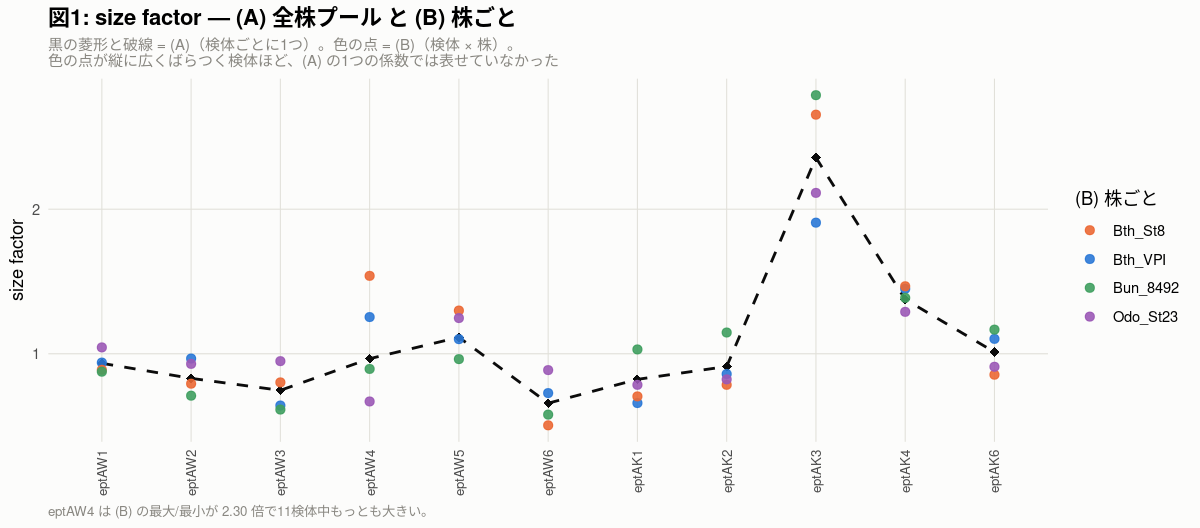

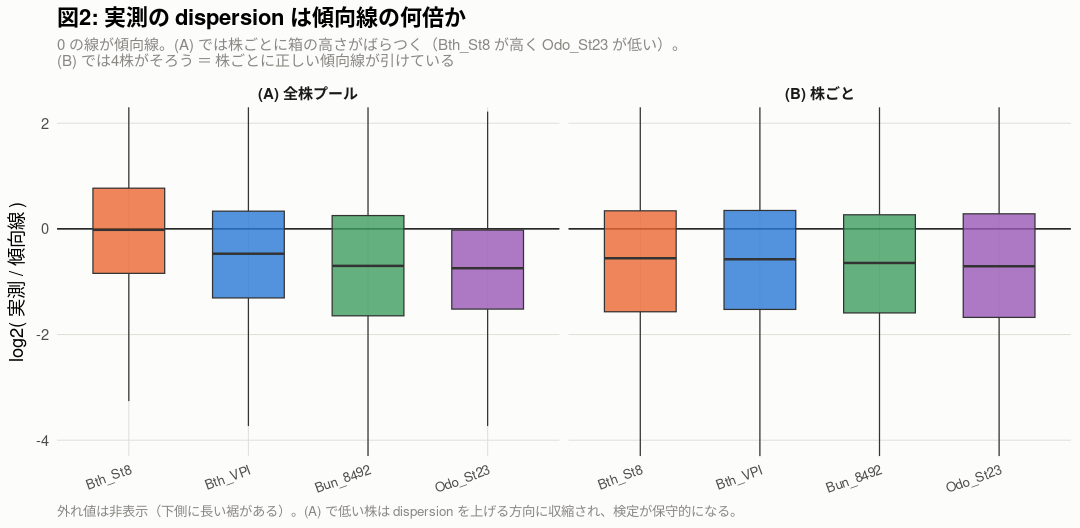

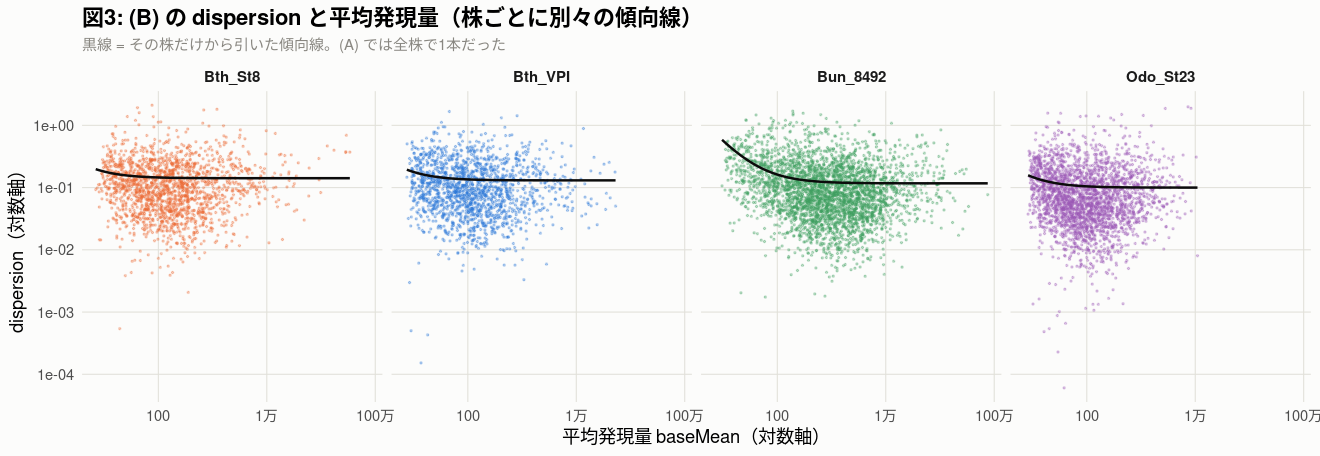

In [22]:
# ── 図: size factor と dispersion を (A) と (B) で比べる ────────────
if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}
col_group  = c(WT = '#2a78d6', KO = '#eb6834')
col_strain = c(Bth_VPI = '#2a78d6', Bth_St8 = '#eb6834',
               Bun_8492 = '#3f9e5f', Odo_St23 = '#9b59b6')
thm = theme_minimal(base_size = 11) +
    theme(panel.background = element_rect(fill = col_surface, colour = NA),
          plot.background  = element_rect(fill = col_surface, colour = NA),
          panel.grid.minor = element_blank(),
          panel.grid.major = element_line(colour = col_grid, linewidth = 0.3),
          strip.text = element_text(face = 'bold', size = 9),
          plot.title = element_text(face = 'bold'),
          plot.subtitle = element_text(colour = col_muted, size = 9),
          plot.caption  = element_text(colour = col_muted, size = 8, hjust = 0))

# 図1: size factor（(A) の1本 vs (B) の4本）
sfl = sf_B %>% tidyr::pivot_longer(-strain, names_to = 'sample', values_to = 'sf') %>%
    mutate(sample = factor(sample, levels = colnames(cnt_de)),
           group  = coldata$group[match(sample, rownames(coldata))])
sfa = data.frame(sample = factor(sf_A$検体, levels = colnames(cnt_de)),
                 sf = sf_A$`size factor`)

options(repr.plot.width = 10, repr.plot.height = 4.4)
p1 = ggplot(sfl, aes(x = sample, y = sf)) +
    geom_line(data = sfa, aes(group = 1), colour = col_text,
              linewidth = 0.8, linetype = 'dashed') +
    geom_point(data = sfa, colour = col_text, size = 2.4, shape = 18) +
    geom_point(aes(colour = strain), size = 2.2, alpha = 0.9) +
    scale_colour_manual(values = col_strain, name = '(B) 株ごと') +
    labs(title = '図1: size factor — (A) 全株プール と (B) 株ごと',
         subtitle = paste0('黒の菱形と破線 = (A)（検体ごとに1つ）。',
                           '色の点 = (B)（検体 × 株）。\n',
                           '色の点が縦に広くばらつく検体ほど、',
                           '(A) の1つの係数では表せていなかった'),
         x = NULL, y = 'size factor',
         caption = 'eptAW4 は (B) の最大/最小が 2.30 倍で11検体中もっとも大きい。') + thm +
    theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5, size = 8))
suppressWarnings(print(p1))

# 図2: 実測/傾向線 の分布を (A) と (B) で比べる（★ 本題）
rat = rbind(
  dd %>% transmute(strain, version = '(A) 全株プール', r = log2(実測_A / 傾向線_A)),
  dd %>% transmute(strain, version = '(B) 株ごと',     r = log2(実測_B / 傾向線_B))) %>%
  mutate(version = factor(version, levels = c('(A) 全株プール','(B) 株ごと')))

options(repr.plot.width = 9, repr.plot.height = 4.4)
p2 = ggplot(rat, aes(x = strain, y = r, fill = strain)) +
    geom_hline(yintercept = 0, colour = col_text, linewidth = 0.4) +
    geom_boxplot(outlier.shape = NA, linewidth = 0.35, width = 0.6, alpha = 0.8) +
    scale_fill_manual(values = col_strain) + guides(fill = 'none') +
    coord_cartesian(ylim = c(-4, 2)) +
    facet_wrap(~ version, nrow = 1) +
    labs(title = '図2: 実測の dispersion は傾向線の何倍か',
         subtitle = paste0('0 の線が傾向線。(A) では株ごとに箱の高さがばらつく',
                           '（Bth_St8 が高く Odo_St23 が低い）。\n',
                           '(B) では4株がそろう ＝ 株ごとに正しい傾向線が引けている'),
         x = NULL, y = 'log2( 実測 / 傾向線 )',
         caption = paste0('外れ値は非表示（下側に長い裾がある）。',
                          '(A) で低い株は dispersion を上げる方向に収縮され、検定が保守的になる。')) + thm +
    theme(axis.text.x = element_text(angle = 20, hjust = 1, size = 8))
suppressWarnings(print(p2))

# 図3: dispersion と平均発現量（(B)、株ごと）
options(repr.plot.width = 11, repr.plot.height = 3.8)
p3 = ggplot(dd, aes(x = baseMean_B, y = 実測_B)) +
    geom_point(aes(colour = strain), size = 0.3, alpha = 0.3) +
    geom_line(aes(y = 傾向線_B), colour = col_text, linewidth = 0.7) +
    scale_x_log10(breaks = c(1, 1e2, 1e4, 1e6), labels = c('1','100','1万','100万')) +
    scale_y_log10() +
    scale_colour_manual(values = col_strain) +
    facet_wrap(~ strain, nrow = 1) + guides(colour = 'none') +
    labs(title = '図3: (B) の dispersion と平均発現量（株ごとに別々の傾向線）',
         subtitle = '黒線 = その株だけから引いた傾向線。(A) では全株で1本だった',
         x = '平均発現量 baseMean（対数軸）', y = 'dispersion（対数軸）') + thm
suppressWarnings(print(p3))

### 考察: 株ごとの size factor と dispersion（セル6図 の結果）

## 結論: **(A) の偏りは (B) で解消されている**

### ★ 傾向線の当てはまりが株間でそろった（図2・Table 2）

**「実測が傾向線より上にある遺伝子の割合」の株間のばらつき:**

| 株 | **(A)** | **(B)** |
|---|---|---|
| Bth_St8 | **49.5%** | 33.6% |
| Bth_VPI | 35.8% | 33.5% |
| Bun_8492 | 31.1% | 31.6% |
| **Odo_St23** | **24.4%** | **32.0%** |
| **株間の幅** | **25.1 ポイント** | **2.1 ポイント** |

**(A) では1本の傾向線がどの株にも合っていなかった**のが、
**(B) では4株とも 31.6〜33.6% にそろう。**
→ **株ごとに正しい傾向線が引けている。**

### dispersion は全株で下がる。特に `Odo_St23`

| 株 | 最終 dispersion (A) | (B) | **比 (B/A)** |
|---|---|---|---|
| **Odo_St23** | 0.1143 | **0.0804** | **0.70** |
| Bth_St8 | 0.1523 | 0.1158 | 0.76 |
| Bth_VPI | 0.1291 | 0.1080 | 0.84 |
| Bun_8492 | 0.1031 | 0.0988 | 0.96 |

**`Odo_St23` が 30% 下がる**のは、(A) で最も強く上げられていたから。
**5_1 セル6 で「`Bun`/`Odo` の検出力低下に注記が要る」と書いた点が、(B) で解消される。**

**※ `Bth_St8` も 24% 下がっている。** (A) の傾向線は `Bth_St8` に合っていた（0.97）が、
それは**他3株を巻き込んで引き上げられた線に `Bth_St8` が乗っていた**ということ。
(B) で `Bth_St8` 自身の線を引くと、やはり実測の方が低い。

## ★ `eptAW4` の正体がここで定量化できた（図1・Table 2）

**同じ検体でも株ごとに size factor が違う。** そのばらつきが最大なのが `eptAW4`。

| 検体 | (A) | Bth_VPI | Bth_St8 | Bun_8492 | Odo_St23 | **(B) の最大/最小** |
|---|---|---|---|---|---|---|
| **eptAW4** | 0.966 | 1.254 | **1.539** | 0.895 | **0.670** | **2.30** |
| eptAW6 | 0.658 | 0.728 | 0.505 | 0.579 | 0.887 | 1.76 |
| eptAK1 | 0.823 | 0.659 | 0.705 | 1.030 | 0.785 | 1.56 |
| eptAK4 | 1.376 | 1.449 | 1.467 | 1.387 | 1.290 | **1.14** |

**`eptAW4` は `Bth_St8` が多く `Odo_St23` が少ない**という偏った構成で、
**(A) の1つの係数（0.966）ではどの株も正しく表せていなかった。**

これが 5_1 で見た6つの外れ値指標（RLE の IQR 1.373 / PC2 −96.1 / 同群内距離 100.2 /
Salmon 整合率 95.66% / `Odo_St23` シェア 2.09%）の**共通の原因**と考えられる。

→ **(B) では株ごとに正しい係数が与えられるので、`eptAW4` の影響は (A) より小さいはず。**
セル11 の感度解析で確かめる。

## セル7図: MA プロットと火山図（(B) 株ごと）

5_1 セル8図 と同じ作り。違いは3点。

|- | 5_1（(A)） | ここ（(B)） |
|---|---|---|
| 株 | 5つ（pME008 を含む） | **4株**（pME008 は除外） |
| 有意の判定 | `padj` | **`padj_pooled`**（(A) と同じ土俵。セル5） |
| LFC | (A) の収縮後 | **(B) の収縮後** |

**色の約束は 5_1 と同じ**: 上昇=赤 / 低下=青 / 有意でない=灰、
eptA マーカーは**金色の菱形（黒縁）**。

### ★ 図1 の見どころ — 黄の破線が 0 に来るか

**黄の破線 = その株の LFC 中央値。**

**(B) では株のシェア変化が除かれているので 0 付近になるはず。**
(A) では `Bth_VPI` −0.107 / `Bun_8492` **+0.315** とずれていた（5_1 セル7 Table 4）。
**これが (B) で消えれば、「(B) は株内の制御だけを見ている」ことの確認になる。**

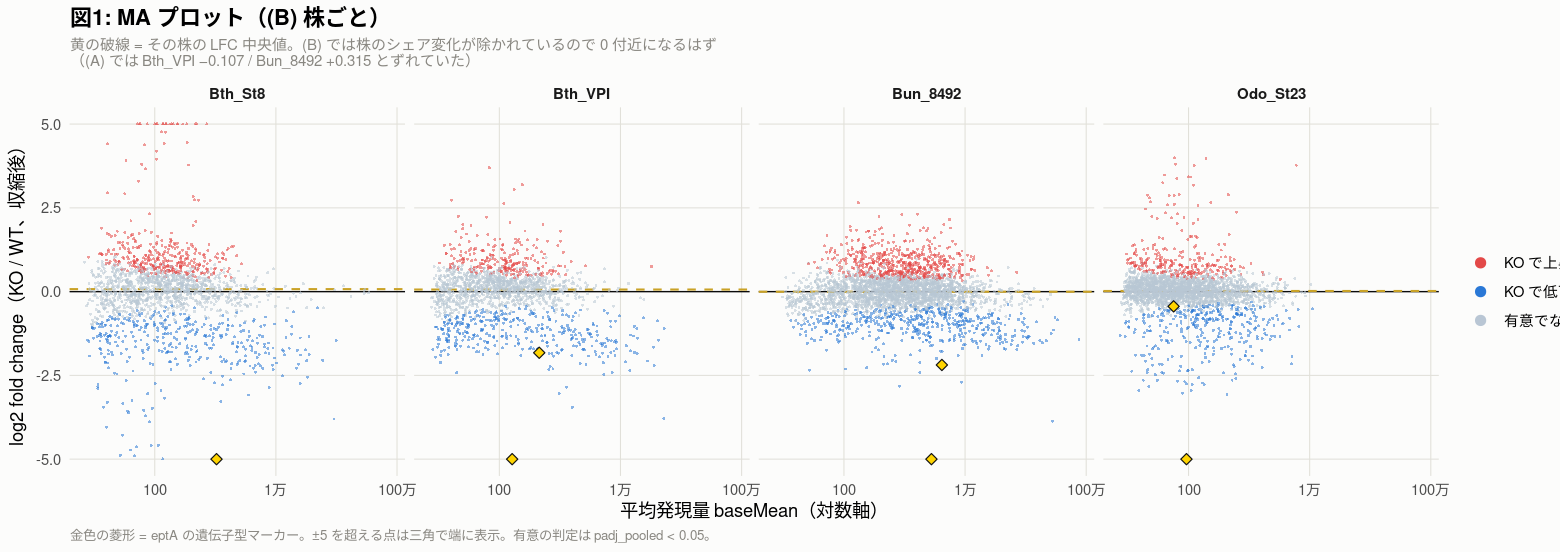

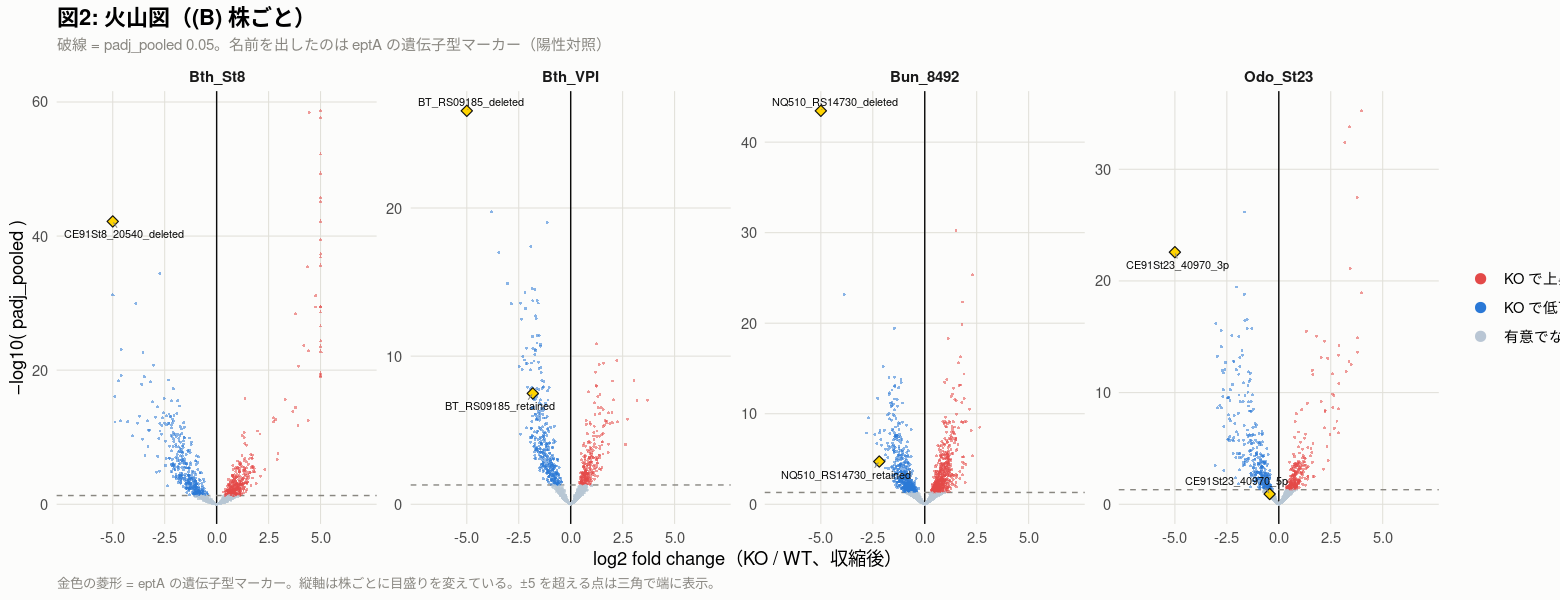

In [23]:
# ── MA プロットと火山図（株ごと）────────────────────────────────
# 5_1 セル8図 と同じ作り。違いは3点。
#   ・(B) なので pME008 が無い（4株）
#   ・有意の判定は padj_pooled を使う（(A) と同じ土俵。セル5）
#   ・横軸/縦軸の LFC は (B) の収縮後の値
#
# 色の約束は 5_1 と同じ: 上昇=赤 / 低下=青 / 有意でない=灰、
# eptA マーカーは金色の菱形（黒縁）
library(ggrepel)

if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}
col_dir = c(`KO で上昇` = '#e34948', `KO で低下` = '#2a78d6', `有意でない` = '#b9c6d4')
col_mk_fill = '#ffd400'; col_mk_line = '#111111'

pltB = de_B %>%
    left_join(feat_de %>% dplyr::select(gene_id, marker), by = 'gene_id') %>%
    filter(!is.na(padj_pooled), !is.na(LFC_B)) %>%
    mutate(向き = ifelse(padj_pooled >= 0.05, '有意でない',
                  ifelse(LFC_B > 0, 'KO で上昇', 'KO で低下')),
           向き = factor(向き, levels = names(col_dir)),
           y_ma = pmax(pmin(LFC_B, 5), -5),
           x_vol = pmax(pmin(LFC_B, 5), -5),
           clipped = abs(LFC_B) > 5)
labB = pltB %>% filter(marker)
medB = pltB %>% group_by(strain) %>% summarise(med = median(LFC_B), .groups = 'drop')

thm = theme_minimal(base_size = 11) +
    theme(panel.background = element_rect(fill = col_surface, colour = NA),
          plot.background  = element_rect(fill = col_surface, colour = NA),
          panel.grid.minor = element_blank(),
          panel.grid.major = element_line(colour = col_grid, linewidth = 0.3),
          strip.text = element_text(face = 'bold', size = 9),
          plot.title = element_text(face = 'bold'),
          plot.subtitle = element_text(colour = col_muted, size = 9),
          plot.caption  = element_text(colour = col_muted, size = 8, hjust = 0))

# 図1: MA プロット
options(repr.plot.width = 13, repr.plot.height = 4.6)
p1 = ggplot(pltB, aes(x = baseMean_B, y = y_ma)) +
    geom_hline(yintercept = 0, colour = col_text, linewidth = 0.4) +
    geom_hline(data = medB, aes(yintercept = med), colour = '#c9a227',
               linewidth = 0.6, linetype = 'dashed') +
    geom_point(aes(colour = 向き, shape = clipped), size = 0.5, alpha = 0.55) +
    geom_point(data = labB, aes(x = baseMean_B, y = y_ma), shape = 23, size = 2.2,
               fill = col_mk_fill, colour = col_mk_line, stroke = 0.5) +
    scale_x_log10(breaks = c(1, 1e2, 1e4, 1e6), labels = c('1','100','1万','100万')) +
    scale_y_continuous(breaks = seq(-5, 5, 2.5)) +
    scale_colour_manual(values = col_dir, name = NULL) +
    scale_shape_manual(values = c(`FALSE` = 16, `TRUE` = 17), guide = 'none') +
    facet_wrap(~ strain, nrow = 1) +
    guides(colour = guide_legend(override.aes = list(size = 2.5, alpha = 1))) +
    labs(title = '図1: MA プロット（(B) 株ごと）',
         subtitle = paste0('黄の破線 = その株の LFC 中央値。',
                           '(B) では株のシェア変化が除かれているので 0 付近になるはず\n',
                           '（(A) では Bth_VPI −0.107 / Bun_8492 +0.315 とずれていた）'),
         x = '平均発現量 baseMean（対数軸）', y = 'log2 fold change（KO / WT、収縮後）',
         caption = paste0('金色の菱形 = eptA の遺伝子型マーカー。',
                          '±5 を超える点は三角で端に表示。有意の判定は padj_pooled < 0.05。')) + thm
suppressWarnings(print(p1))

# 図2: 火山図
options(repr.plot.width = 13, repr.plot.height = 5.0)
p2 = ggplot(pltB, aes(x = x_vol, y = -log10(padj_pooled))) +
    geom_vline(xintercept = 0, colour = col_text, linewidth = 0.4) +
    geom_hline(yintercept = -log10(0.05), linetype = 'dashed',
               colour = col_muted, linewidth = 0.4) +
    geom_point(aes(colour = 向き, shape = clipped), size = 0.5, alpha = 0.55) +
    geom_point(data = labB, aes(x = x_vol, y = -log10(padj_pooled)), shape = 23,
               size = 2.2, fill = col_mk_fill, colour = col_mk_line, stroke = 0.5) +
    geom_text_repel(data = labB, aes(x = x_vol, y = -log10(padj_pooled), label = gene_id),
                    size = 2.3, colour = col_text, seed = 1, direction = 'y',
                    nudge_x = ifelse(labB$LFC_B < 0, -1.6, 1.6),
                    min.segment.length = 0, segment.colour = col_muted,
                    segment.size = 0.3, box.padding = 0.3, max.overlaps = Inf) +
    scale_x_continuous(limits = c(-7, 7), breaks = seq(-5, 5, 2.5)) +
    scale_colour_manual(values = col_dir, name = NULL) +
    scale_shape_manual(values = c(`FALSE` = 16, `TRUE` = 17), guide = 'none') +
    facet_wrap(~ strain, nrow = 1, scales = 'free_y') +
    guides(colour = guide_legend(override.aes = list(size = 2.5, alpha = 1))) +
    labs(title = '図2: 火山図（(B) 株ごと）',
         subtitle = '破線 = padj_pooled 0.05。名前を出したのは eptA の遺伝子型マーカー（陽性対照）',
         x = 'log2 fold change（KO / WT、収縮後）', y = '−log10( padj_pooled )',
         caption = paste0('金色の菱形 = eptA の遺伝子型マーカー。',
                          '縦軸は株ごとに目盛りを変えている。±5 を超える点は三角で端に表示。')) + thm
suppressWarnings(print(p2))

## セル7図（英語版）: MA plot / Volcano plot

**中身はセル7図 と同じ2枚で、文字だけ英語にしたもの。**

```r
ggsave('figB_MA_bystrain.pdf',      p1_ma_en,  width = 13, height = 4.6)
ggsave('figB_volcano_bystrain.pdf', p2_vol_en, width = 13, height = 5.0)
```

| 日本語版 | 英語版 |
|---|---|
| KO で上昇 / KO で低下 / 有意でない | `Up in KO` / `Down in KO` / `n.s.` |

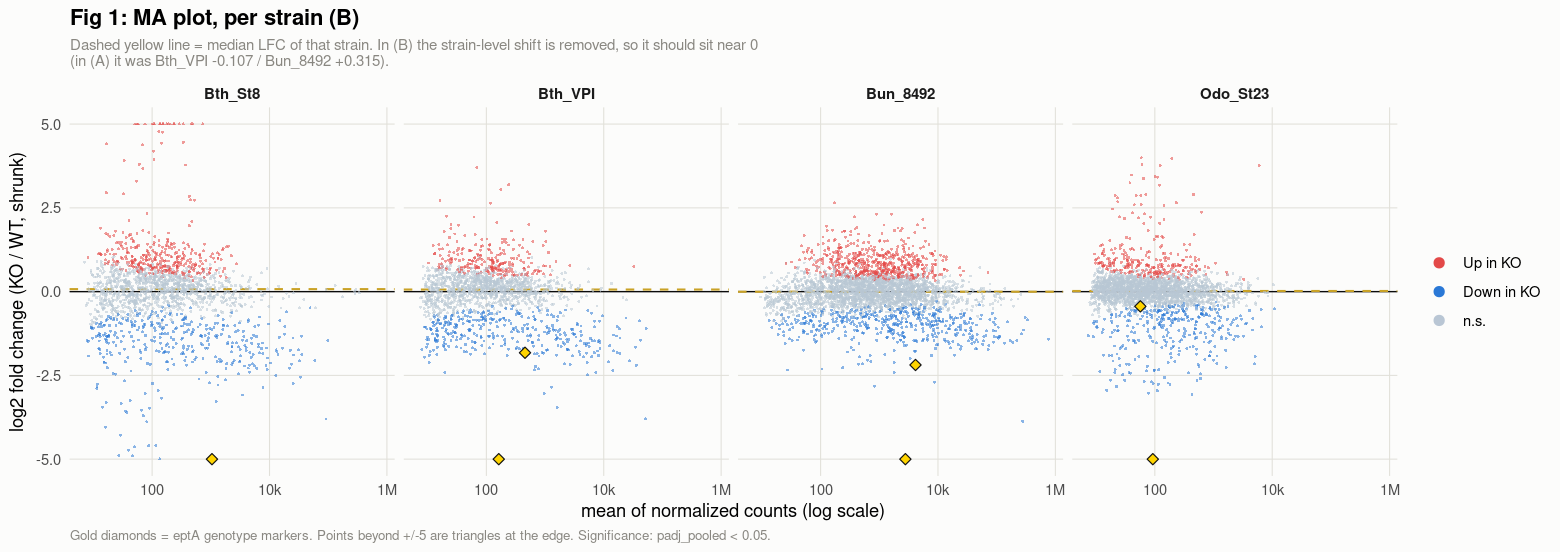

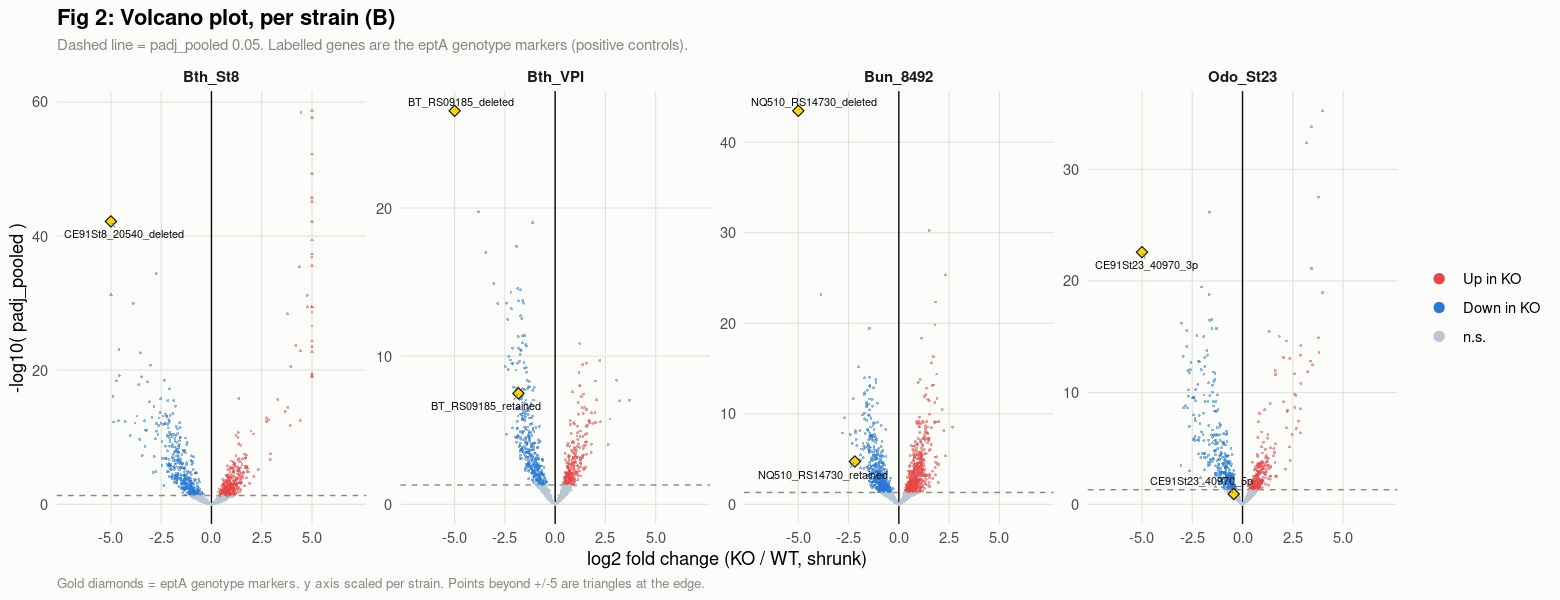

In [24]:
# ── Same figures, English labels（PDF / EPS 出力用）──────────────
# セル7図 と中身は同じで、文字だけ英語にしたもの。
# 5_1 セル8図 と同じ作り。違いは3点。
#   ・(B) なので pME008 が無い（4株）
#   ・有意の判定は padj_pooled を使う（(A) と同じ土俵。セル5）
#   ・横軸/縦軸の LFC は (B) の収縮後の値
#
# 色の約束は 5_1 と同じ: 上昇=赤 / 低下=青 / 有意でない=灰、
# eptA マーカーは金色の菱形（黒縁）
library(ggplot2); library(ggrepel)

if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}
col_dir_en = c(`Up in KO` = '#e34948', `Down in KO` = '#2a78d6', `n.s.` = '#b9c6d4')
col_mk_fill = '#ffd400'; col_mk_line = '#111111'

pltB_en = de_B %>%
    left_join(feat_de %>% dplyr::select(gene_id, marker), by = 'gene_id') %>%
    filter(!is.na(padj_pooled), !is.na(LFC_B)) %>%
    mutate(direction = ifelse(padj_pooled >= 0.05, 'n.s.',
                      ifelse(LFC_B > 0, 'Up in KO', 'Down in KO')),
           direction = factor(direction, levels = names(col_dir_en)),
           y_ma = pmax(pmin(LFC_B, 5), -5),
           x_vol = pmax(pmin(LFC_B, 5), -5),
           clipped = abs(LFC_B) > 5)
labB_en = pltB_en %>% filter(marker)
medB_en = pltB_en %>% group_by(strain) %>% summarise(med = median(LFC_B), .groups = 'drop')

thm_en = theme_minimal(base_size = 11) +
    theme(panel.background = element_rect(fill = col_surface, colour = NA),
          plot.background  = element_rect(fill = col_surface, colour = NA),
          panel.grid.minor = element_blank(),
          panel.grid.major = element_line(colour = col_grid, linewidth = 0.3),
          strip.text = element_text(face = 'bold', size = 9),
          plot.title = element_text(face = 'bold'),
          plot.subtitle = element_text(colour = col_muted, size = 9),
          plot.caption  = element_text(colour = col_muted, size = 8, hjust = 0))

# 図1: MA プロット
options(repr.plot.width = 13, repr.plot.height = 4.6)
p1_ma_en = ggplot(pltB_en, aes(x = baseMean_B, y = y_ma)) +
    geom_hline(yintercept = 0, colour = col_text, linewidth = 0.4) +
    geom_hline(data = medB_en, aes(yintercept = med), colour = '#c9a227',
               linewidth = 0.6, linetype = 'dashed') +
    geom_point(aes(colour = direction, shape = clipped), size = 0.5, alpha = 0.55) +
    geom_point(data = labB_en, aes(x = baseMean_B, y = y_ma), shape = 23, size = 2.2,
               fill = col_mk_fill, colour = col_mk_line, stroke = 0.5) +
    scale_x_log10(breaks = c(1, 1e2, 1e4, 1e6), labels = c('1','100','10k','1M')) +
    scale_y_continuous(breaks = seq(-5, 5, 2.5)) +
    scale_colour_manual(values = col_dir_en, name = NULL) +
    scale_shape_manual(values = c(`FALSE` = 16, `TRUE` = 17), guide = 'none') +
    facet_wrap(~ strain, nrow = 1) +
    guides(colour = guide_legend(override.aes = list(size = 2.5, alpha = 1))) +
    labs(title = 'Fig 1: MA plot, per strain (B)',
         subtitle = paste0('Dashed yellow line = median LFC of that strain. ',
                           'In (B) the strain-level shift is removed, so it should sit near 0\n',
                           '(in (A) it was Bth_VPI -0.107 / Bun_8492 +0.315).'),
         x = 'mean of normalized counts (log scale)',
         y = 'log2 fold change (KO / WT, shrunk)',
         caption = paste('Gold diamonds = eptA genotype markers.',
                         'Points beyond +/-5 are triangles at the edge.',
                         'Significance: padj_pooled < 0.05.')) + thm_en
suppressWarnings(print(p1_ma_en))

# 図2: 火山図
options(repr.plot.width = 13, repr.plot.height = 5.0)
p2_vol_en = ggplot(pltB_en, aes(x = x_vol, y = -log10(padj_pooled))) +
    geom_vline(xintercept = 0, colour = col_text, linewidth = 0.4) +
    geom_hline(yintercept = -log10(0.05), linetype = 'dashed',
               colour = col_muted, linewidth = 0.4) +
    geom_point(aes(colour = direction, shape = clipped), size = 0.5, alpha = 0.55) +
    geom_point(data = labB_en, aes(x = x_vol, y = -log10(padj_pooled)), shape = 23,
               size = 2.2, fill = col_mk_fill, colour = col_mk_line, stroke = 0.5) +
    geom_text_repel(data = labB_en, aes(x = x_vol, y = -log10(padj_pooled), label = gene_id),
                    size = 2.3, colour = col_text, seed = 1, direction = 'y',
                    nudge_x = ifelse(labB_en$LFC_B < 0, -1.6, 1.6),
                    min.segment.length = 0, segment.colour = col_muted,
                    segment.size = 0.3, box.padding = 0.3, max.overlaps = Inf) +
    scale_x_continuous(limits = c(-7, 7), breaks = seq(-5, 5, 2.5)) +
    scale_colour_manual(values = col_dir_en, name = NULL) +
    scale_shape_manual(values = c(`FALSE` = 16, `TRUE` = 17), guide = 'none') +
    facet_wrap(~ strain, nrow = 1, scales = 'free_y') +
    guides(colour = guide_legend(override.aes = list(size = 2.5, alpha = 1))) +
    labs(title = 'Fig 2: Volcano plot, per strain (B)',
         subtitle = paste('Dashed line = padj_pooled 0.05.',
                          'Labelled genes are the eptA genotype markers (positive controls).'),
         x = 'log2 fold change (KO / WT, shrunk)', y = '-log10( padj_pooled )',
         caption = paste('Gold diamonds = eptA genotype markers.',
                         'y axis scaled per strain. Points beyond +/-5 are triangles at the edge.')) + thm_en
suppressWarnings(print(p2_vol_en))

### 考察: MA / 火山図（セル7図 の結果）

## ★ 結論: 株のシェア変化が (B) で消えている

### LFC 中央値が4株とも 0 付近になった

| 株 | **(A)** | **(B)** | 差 |
|---|---|---|---|
| Bth_St8 | −0.081 | +0.067 | +0.148 |
| Bth_VPI | −0.107 | +0.050 | +0.157 |
| **Bun_8492** | **+0.315** | **−0.018** | **−0.333** |
| Odo_St23 | −0.181 | +0.015 | +0.196 |
| **株間の幅** | **0.496** | **0.085** | — |

**(B) では株間の幅が 0.496 → 0.085 と 1/6 に縮んだ。**
**「(B) は株内の制御だけを見ている」ことの検算になっている**（セル9 でさらに詳しく見る）。

## ★★ `Bun_8492` の「上昇優勢」は消えた

**これが (A) と (B) の最大の違い。**

| 株 | (A) 上昇 / 低下 | **(B) 上昇 / 低下** |
|---|---|---|
| **Bun_8492** | **1,173 / 224（5.2 : 1）** | **552 / 482（1.15 : 1）** |
| Bth_St8 | 199 / 402 | 362 / 371 |
| Bth_VPI | 126 / 409 | 240 / 358 |
| Odo_St23 | 117 / 475 | 271 / 328 |

**(A) で `Bun_8492` の遺伝子が 5.2 : 1 で上昇優勢だったのは、
菌叢構成の変化（シェア 72.4% → 79.7%）であって、
菌1細胞あたりの発現制御ではなかった。**

**(B) では 1.15 : 1 とほぼ均衡する。**

**これは過去プロジェクト T19 の PTS の例**
（(A) padj 1.1e-12 / (B) padj 0.10、実体は *Enterococcus* が3倍に増えただけ）
**と同じことが、今回のデータでも起きていたということ。**

→ **(A) の「`Bun_8492` が群集として何を出しているか」は正しい**（宿主はそれにさらされている）が、
**「`Bun_8492` が発現を上げた」と書いてはいけない**（CLAUDE.md §7 ステージ5）。

## 株ごとの DEG 数は (A) と (B) で向きが逆に動く

| 株 | (A) | (B) | 差 |
|---|---|---|---|
| **Bun_8492** | 1,397 | **1,034** | **−363** |
| **Bth_St8** | 601 | **733** | **+132** |
| Bth_VPI | 535 | 598 | +63 |
| Odo_St23 | 592 | 599 | +7 |

- **`Bun_8492` は減る** — (A) で検出されていた DEG の多くがシェア変化由来だったため
- **`Bth_St8` は増える** — (B) で dispersion が 24% 下がり検出力が上がったため（セル6）

**どちらも「(A) が間違っていた」のではなく、見ている問いが違う。**

## 陽性対照は (B) でも機能している

4つの `_deleted` / `_3p` が**金色の菱形で左上の隅**に来ている（図2）。
`_retained` / `_5p` は中ほど。**(A) と同じ位置関係。**

## セル8: ★ (A) vs (B) を遺伝子ごとに比べる（このnotebook の本題）

同じ 9,785 遺伝子（pME008 を除く）について、**同じ検定・同じ収縮で、
size factor の範囲だけが違う**2つの結果を1対1で突き合わせる。

### 最も情報量が多いのは「片方だけで有意」な遺伝子

| 分類 | 意味 |
|---|---|
| **両方で有意** | 菌量にも制御にもよらず動いている |
| **(A) のみ有意** | **菌叢構成の変化で説明がつく**（菌が増減しただけ） |
| **(B) のみ有意** | **(A) では構成変化に埋もれて見えなかった株内の制御** |

### ★ 「有意でない」と「検定されていない」を分ける

DESeq2 は**独立フィルタ**と**外れ値判定（Cook 距離）**で一部の遺伝子の `padj` を **NA** にする。
これは「有意でない」のとは別物なので、分類で区別する。
（実際には13遺伝子だけなので全体の判断には影響しない）

### 土俵をそろえる

**(A) は `padj`、(B) は `padj_pooled`** を使う。
**どちらも全遺伝子で BH を1回**なので、同じ基準で比べられる。

In [25]:
# ── ★ (A) vs (B) を遺伝子ごとに比べる（このnotebook の本題）─────────
# 同じ 9,785 遺伝子（pME008 を除く）について、同じ検定・同じ収縮で、
# size factor の範囲だけが違う2つの結果を1対1で突き合わせる。
#
# 最も情報量が多いのは【片方だけで有意】な遺伝子。
#   (A) のみ有意 … 菌叢構成の変化で説明がつく（菌が増減しただけ）
#   (B) のみ有意 … (A) では構成変化に埋もれて見えなかった株内の制御
#
# ★ (A) は padj、(B) は padj_pooled を使う（どちらも全遺伝子で BH 1回＝同じ土俵）

AB = de_B %>%
    dplyr::select(gene_id, strain, LFC_B, padj_pooled, padj_bystrain,
                  stat_B, normB_diff) %>%
    inner_join(de_A %>% dplyr::select(gene_id, product, marker, baseMean,
                                      LFC_A = LFC_shrunk, padj_A = padj,
                                      stat_A = stat_Wald, norm_diff),
               by = 'gene_id') %>%
    mutate(sigA = !is.na(padj_A) & padj_A < 0.05,
           sigB = !is.na(padj_pooled) & padj_pooled < 0.05,
           naA = is.na(padj_A), naB = is.na(padj_pooled),
           # ★「有意でない」と「そもそも検定されていない(NA)」は別物なので分ける。
           #   NA は独立フィルタか外れ値判定（Cook 距離）で外れたもの
           分類 = case_when(
               sigA &  sigB              ~ '両方で有意',
               sigA & !sigB & !naB       ~ '(A) のみ有意',
               sigA &  naB               ~ '(A) 有意 / (B) 未検定',
              !sigA &  sigB & !naA       ~ '(B) のみ有意',
               naA  &  sigB              ~ '(B) 有意 / (A) 未検定',
               TRUE                      ~ 'どちらも有意でない'),
           分類 = factor(分類, levels = c('両方で有意','(A) のみ有意','(B) のみ有意',
                                          '(A) 有意 / (B) 未検定','(B) 有意 / (A) 未検定',
                                          'どちらも有意でない')))

cat(sprintf("■ 比較した遺伝子: %s（pME008 の10遺伝子を除く）\n",
            format(nrow(AB), big.mark = ',')))

cat("\n■ Table 1: 4分類（全体）\n")
AB %>% dplyr::count(分類, name = 'n') %>%
    mutate(pct = round(100 * n / sum(n), 1)) %>% as.data.frame()

cat("\n■ Table 2: 4分類（株ごと）\n")
AB %>% dplyr::count(strain, 分類, name = 'n') %>%
    tidyr::pivot_wider(names_from = 分類, values_from = n, values_fill = 0) %>%
    as.data.frame()

cat("\n■ Table 3: LFC の一致（株ごと）\n")
cat("   差の中央値 … (B) − (A)。株のシェア変化の分だけずれる\n")
AB %>% group_by(strain) %>%
    summarise(n = dplyr::n(),
              LFC相関 = round(cor(LFC_A, LFC_B, use = 'complete.obs'), 4),
              `差の中央値` = round(median(LFC_B - LFC_A, na.rm = TRUE), 3),
              `向きが逆(両方有意)` = sum(分類 == '両方で有意' &
                                         sign(LFC_A) != sign(LFC_B), na.rm = TRUE),
              .groups = 'drop') %>% as.data.frame()

cat("\n■ Table 4: (A) のみ有意の代表例（菌叢構成の変化で説明がつく側）\n")
cat("   ★ (B) でも検定はされていて、padj が 0.05 を超えているものだけ\n")
AB %>% filter(分類 == '(A) のみ有意') %>% arrange(desc(abs(LFC_A))) %>% head(12) %>%
    mutate(LFC_A = round(LFC_A, 2), LFC_B = round(LFC_B, 2),
           padj_A = signif(padj_A, 2), padj_B = signif(padj_pooled, 2),
           product = substr(product, 1, 36)) %>%
    dplyr::select(gene_id, strain, LFC_A, padj_A, LFC_B, padj_B, product) %>%
    as.data.frame()

cat("\n■ Table 5: (B) のみ有意の代表例（(A) では構成変化に埋もれていた側）\n")
cat("   ★ (A) でも検定はされていて、padj が 0.05 を超えているものだけ\n")
AB %>% filter(分類 == '(B) のみ有意') %>% arrange(desc(abs(LFC_B))) %>% head(12) %>%
    mutate(LFC_A = round(LFC_A, 2), LFC_B = round(LFC_B, 2),
           padj_A = signif(padj_A, 2), padj_B = signif(padj_pooled, 2),
           product = substr(product, 1, 36)) %>%
    dplyr::select(gene_id, strain, LFC_A, padj_A, LFC_B, padj_B, product) %>%
    as.data.frame()

■ 比較した遺伝子: 9,785（pME008 の10遺伝子を除く）

■ Table 1: 4分類（全体）


分類,n,pct
<fct>,<int>,<dbl>
両方で有意,2269,23.2
(A) のみ有意,851,8.7
(B) のみ有意,687,7.0
(A) 有意 / (B) 未検定,5,0.1
(B) 有意 / (A) 未検定,8,0.1
どちらも有意でない,5965,61.0



■ Table 2: 4分類（株ごと）


strain,両方で有意,(A) のみ有意,(B) のみ有意,(B) 有意 / (A) 未検定,どちらも有意でない,(A) 有意 / (B) 未検定
<chr>,<int>,<int>,<int>,<int>,<int>,<int>
Bth_St8,566,35,164,3,1062,0
Bth_VPI,484,51,114,0,1063,0
Bun_8492,776,621,253,5,1737,0
Odo_St23,443,144,156,0,2103,5



■ Table 3: LFC の一致（株ごと）
   差の中央値 … (B) − (A)。株のシェア変化の分だけずれる


strain,n,LFC相関,差の中央値,向きが逆(両方有意)
<chr>,<int>,<dbl>,<dbl>,<int>
Bth_St8,1830,0.9981,0.160,0
Bth_VPI,1712,0.9988,0.170,0
Bun_8492,3392,0.9950,-0.369,0
Odo_St23,2851,0.9960,0.232,0



■ Table 4: (A) のみ有意の代表例（菌叢構成の変化で説明がつく側）
   ★ (B) でも検定はされていて、padj が 0.05 を超えているものだけ


,gene_id,strain,LFC_A,padj_A,LFC_B,padj_B,product
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,NQ510_RS01965,Bun_8492,2.06,0.0190,0.66,0.056,potassium-transporting ATPase subuni
2,NQ510_RS07315,Bun_8492,1.63,0.0073,0.97,0.051,YraN family protein
3,NQ510_RS02805,Bun_8492,1.51,0.0089,0.94,0.053,cellulase family glycosylhydrolase
4,NQ510_RS15510,Bun_8492,1.47,0.0140,0.82,0.076,UpxY family transcription antitermin
5,NQ510_RS13315,Bun_8492,1.43,0.0050,0.86,0.062,DUF2149 domain-containing protein
6,NQ510_RS16455,Bun_8492,1.39,0.0083,0.86,0.061,sugar transferase
7,NQ510_RS16815,Bun_8492,1.36,0.0160,0.71,0.099,cytochrome c nitrite reductase small
8,NQ510_RS14585,Bun_8492,1.35,0.0078,0.86,0.057,2-iminoacetate synthase ThiH
9,NQ510_RS00665,Bun_8492,1.34,0.0120,0.84,0.062,glycoside hydrolase family 125 prote



■ Table 5: (B) のみ有意の代表例（(A) では構成変化に埋もれていた側）


   ★ (A) でも検定はされていて、padj が 0.05 を超えているものだけ


,gene_id,strain,LFC_A,padj_A,LFC_B,padj_B,product
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,CE91St8_44930,Bth_St8,0.78,0.120,1.41,0.01300,hypothetical protein
2,CE91St8_21950,Bth_St8,0.91,0.052,1.36,0.00280,porin
3,NQ510_RS02200,Bun_8492,-0.86,0.051,-1.35,0.00370,DUF4476 domain-containing protein
4,CE91St8_44920,Bth_St8,0.75,0.130,1.28,0.01900,SusC/RagA family TonB-linked outer m
5,BT_RS15560,Bth_VPI,0.90,0.075,1.28,0.01300,thioredoxin family protein
6,NQ510_RS07250,Bun_8492,-0.85,0.057,-1.19,0.00910,nucleoside 2-deoxyribosyltransferase
7,CE91St8_08010,Bth_St8,0.76,0.070,1.17,0.00095,serine acetyltransferase
8,NQ510_RS07880,Bun_8492,-0.75,0.059,-1.17,0.00280,FecR family protein
9,BT_RS08105,Bth_VPI,0.86,0.072,1.16,0.01200,HAMP domain-containing sensor histid


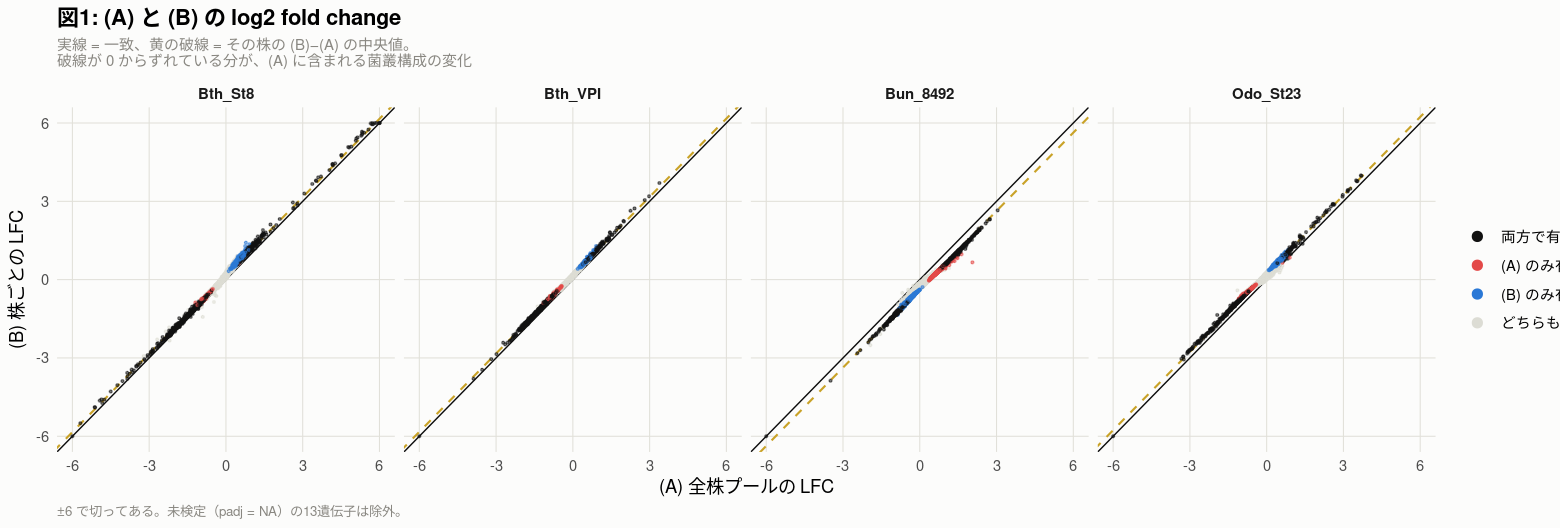

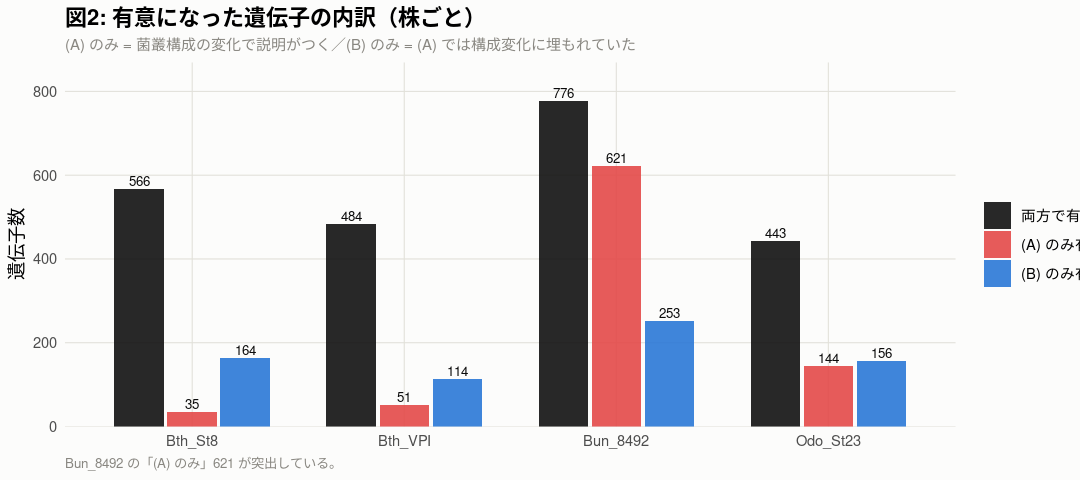

In [26]:
# ── 図: (A) と (B) の LFC を遺伝子ごとに突き合わせる ────────────────
if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}
col_cls = c(`両方で有意` = '#111111', `(A) のみ有意` = '#e34948',
            `(B) のみ有意` = '#2a78d6', `どちらも有意でない` = '#dcdcd4')
thm = theme_minimal(base_size = 11) +
    theme(panel.background = element_rect(fill = col_surface, colour = NA),
          plot.background  = element_rect(fill = col_surface, colour = NA),
          panel.grid.minor = element_blank(),
          panel.grid.major = element_line(colour = col_grid, linewidth = 0.3),
          strip.text = element_text(face = 'bold', size = 9),
          plot.title = element_text(face = 'bold'),
          plot.subtitle = element_text(colour = col_muted, size = 9),
          plot.caption  = element_text(colour = col_muted, size = 8, hjust = 0))

# 未検定の13遺伝子は図から外す（軸に載らないため）
ABf = AB %>% filter(分類 %in% names(col_cls)) %>%
    mutate(分類 = factor(分類, levels = names(col_cls))) %>%
    arrange(desc(分類 == 'どちらも有意でない'))
off = AB %>% group_by(strain) %>%
    summarise(d = median(LFC_B - LFC_A, na.rm = TRUE), .groups = 'drop')

options(repr.plot.width = 13, repr.plot.height = 4.4)
p1 = ggplot(ABf %>% arrange(desc(分類 == 'どちらも有意でない')),
            aes(x = pmax(pmin(LFC_A, 6), -6), y = pmax(pmin(LFC_B, 6), -6))) +
    geom_abline(slope = 1, intercept = 0, colour = col_text, linewidth = 0.4) +
    geom_abline(data = off, aes(slope = 1, intercept = d), colour = '#c9a227',
                linewidth = 0.6, linetype = 'dashed') +
    geom_point(aes(colour = 分類), size = 0.5, alpha = 0.55) +
    scale_colour_manual(values = col_cls, name = NULL) +
    facet_wrap(~ strain, nrow = 1) +
    guides(colour = guide_legend(override.aes = list(size = 2.5, alpha = 1))) +
    labs(title = '図1: (A) と (B) の log2 fold change',
         subtitle = paste0('実線 = 一致、黄の破線 = その株の (B)−(A) の中央値。\n',
                           '破線が 0 からずれている分が、(A) に含まれる菌叢構成の変化'),
         x = '(A) 全株プールの LFC', y = '(B) 株ごとの LFC',
         caption = '±6 で切ってある。未検定（padj = NA）の13遺伝子は除外。') + thm
suppressWarnings(print(p1))

# 図2: 4分類の内訳（株ごと）
options(repr.plot.width = 9, repr.plot.height = 4)
p2 = ABf %>% filter(分類 != 'どちらも有意でない') %>%
    dplyr::count(strain, 分類, name = 'n') %>%
    ggplot(aes(x = strain, y = n, fill = 分類)) +
    geom_col(position = position_dodge(width = 0.75), width = 0.7, alpha = 0.9) +
    geom_text(aes(label = n), position = position_dodge(width = 0.75),
              vjust = -0.3, size = 2.8, colour = col_text) +
    scale_fill_manual(values = col_cls[1:3], name = NULL) +
    scale_y_continuous(expand = expansion(mult = c(0, 0.12))) +
    labs(title = '図2: 有意になった遺伝子の内訳（株ごと）',
         subtitle = paste0('(A) のみ = 菌叢構成の変化で説明がつく／',
                           '(B) のみ = (A) では構成変化に埋もれていた'),
         x = NULL, y = '遺伝子数',
         caption = 'Bun_8492 の「(A) のみ」621 が突出している。') + thm
suppressWarnings(print(p2))

### 考察: (A) vs (B) の遺伝子ごとの比較（セル8 の結果）

## 結論: **(A) の DEG の 27% は菌叢構成の変化で説明がつく。向きが逆の遺伝子は1つも無い。**

### Table 1 — 4分類

| 分類 | 遺伝子数 | 割合 |
|---|---|---|
| 両方で有意 | 2,269 | 23.2% |
| **(A) のみ有意** | **851** | **8.7%** |
| **(B) のみ有意** | **687** | **7.0%** |
| どちらも有意でない | 5,965 | 61.0% |
| 検定されていない（NA）| 13 | 0.1% |

**(A) の DEG 3,120 のうち 851（27.3%）が (B) では有意でなくなる。**

### ★★ Table 2 — `Bun_8492` に集中している

| 株 | 両方 | **(A) のみ** | **(B) のみ** |
|---|---|---|---|
| **Bun_8492** | 776 | **621** | 253 |
| Odo_St23 | 443 | 144 | 156 |
| Bth_VPI | 484 | 51 | 114 |
| Bth_St8 | 566 | 35 | **164** |

**「(A) のみ有意」851 のうち 621（73%）が `Bun_8492`。**
`Bun_8492` の (A) DEG 1,397 のうち **44% が構成変化由来**だったことになる。

セル7 で見た「上昇優勢が 5.2:1 → 1.15:1 に消える」のと同じ現象を、
遺伝子単位で数えたもの。

**`Bth_St8` は逆で、「(B) のみ有意」が 164 と多い。**
(B) で dispersion が 24% 下がって検出力が上がったため（セル6）。

### Table 3 — LFC はほぼ平行移動

| 株 | LFC 相関 | **(B)−(A) の中央値** | 向きが逆 |
|---|---|---|---|
| Bth_St8 | 0.9981 | **+0.160** | **0** |
| Bth_VPI | 0.9988 | **+0.170** | **0** |
| **Bun_8492** | 0.9950 | **−0.369** | **0** |
| Odo_St23 | 0.9960 | **+0.232** | **0** |

**相関 0.995〜0.999 で、差は株ごとにほぼ一定のオフセット。**
図1 で黄の破線（(B)−(A) の中央値）が実線とほぼ平行なのがそれ。

**向きが逆になった遺伝子は4株とも0件。**
→ **(A) と (B) は矛盾しない。** 同じ変化を違う基準で測っているだけ。

## 具体例

### (A) のみ有意 — `Bun_8492` の境界例

`NQ510_RS01965`（LFC_A +2.06, padj_A 0.019 → LFC_B +0.66, **padj_B 0.056**）など、
**(B) では padj が 0.051〜0.099 と 0.05 のすぐ上**に並ぶ。
**−0.369 のオフセット分だけ下がって境界を割った**という形で、
「(A) が偽陽性」でも「(B) が見落とし」でもない。

**※ `NQ510_RS15510` は `UpxY family transcription antiterminator`**
（LFC_A +1.47 → LFC_B +0.82）。**`Bun_8492` にも CPS 座位の制御因子がある。**
セル13 の検討で見つけた `Bun_8492` の PUL とは別。

### (B) のみ有意 — (A) で埋もれていたもの

| gene_id | 株 | LFC_A (padj) | LFC_B (padj) | product |
|---|---|---|---|---|
| `CE91St8_21950` | Bth_St8 | +0.91 (0.052) | **+1.36 (2.8e-03)** | porin |
| **`BT_RS15560`** | Bth_VPI | +0.90 (0.075) | **+1.28 (1.3e-02)** | **thioredoxin family protein** |
| **`CE91St8_08010`** | Bth_St8 | +0.76 (0.070) | **+1.17 (9.5e-04)** | **serine acetyltransferase** |
| `NQ510_RS03875` | Bun_8492 | −0.98 (NA) | −1.35 (1.7e-03) | SusC/RagA |

**`thioredoxin` と `serine acetyltransferase` が (B) で初めて有意になる。**
`serine acetyltransferase` は**システイン合成の前段**（セリン → O-アセチルセリン → システイン）。

5_1 で見つけた所見（**cysteine synthase が3株で低下**、`Bun_8492` の**抗酸化系が低下**）と
**同じ経路の遺伝子が、(B) では逆に上昇している。**

→ **硫黄代謝・レドックス系は (A) と (B) で向きが食い違う可能性がある。**
**ステージ6 の2パネル図で最も注目すべき経路。** ここでは個別遺伝子の観察にとどめる。

## 申し送り

| 項目 | 内容 |
|---|---|
| **(A) と (B) は矛盾しない** | 向きが逆の遺伝子は0件。差は株ごとのほぼ一定のオフセット |
| **`Bun_8492` の (A) DEG は 44% が構成変化由来** | 本文で「Bun が発現を上げた」と書かない |
| **硫黄代謝・レドックス系** | (A) では低下（cysteine synthase 等）、(B) では上昇（thioredoxin・serine acetyltransferase）。**経路解析で必ず両パネルを見る** |

## セル9図: 個別遺伝子の箱ひげ図（(B) 株ごと正規化）

5_1 セル14図 と同じ作り。**正規化が株ごとになっている点だけ**が違う。

**※ 当初の予定にあった「セル9（株のシフトが消えているかの検算）」は、
セル7（LFC 中央値が4株とも 0 付近）とセル8（(B)−(A) の中央値が株ごとにほぼ一定）で
済んだので省いた。**

### 図の構成（4枚）

| 図 | 中身 |
|---|---|
| 図1 | (B) で KO 上昇の遺伝子 top20 |
| 図2 | (B) で KO 低下の遺伝子 top20 |
| 図3 | eptA の遺伝子型マーカー（陽性対照） |
| **図4** | **★ このnotebook 固有。同じ遺伝子を (A) と (B) の正規化で並べる** |

### ★ 図4 の読み方

セル8 で分類した**「(A) のみ有意」「(B) のみ有意」の代表例**を取り、
**同じ検体の同じ生カウント**を2通りの正規化で描いている。

| 段 | size factor の計算範囲 |
|---|---|
| 上段 | 全 9,795 遺伝子（(A)） |
| 下段 | その株の遺伝子だけ（(B)） |

**遺伝子ごとに発現量の桁が違う**ので、**各遺伝子の WT 平均で割った比の log2** で描く。

- **破線 = 0**（WT の平均）
- **KO の箱の位置がその遺伝子の LFC にあたる**
- **上段と下段で KO の箱の位置が変われば、それが正規化の違いによる分**

`facet_grid` は行ごとにしか目盛りを共有できず、`ggh4x` もこの環境に無いため、
**比に直して全遺伝子を同じ軸に載せる**方法をとった。

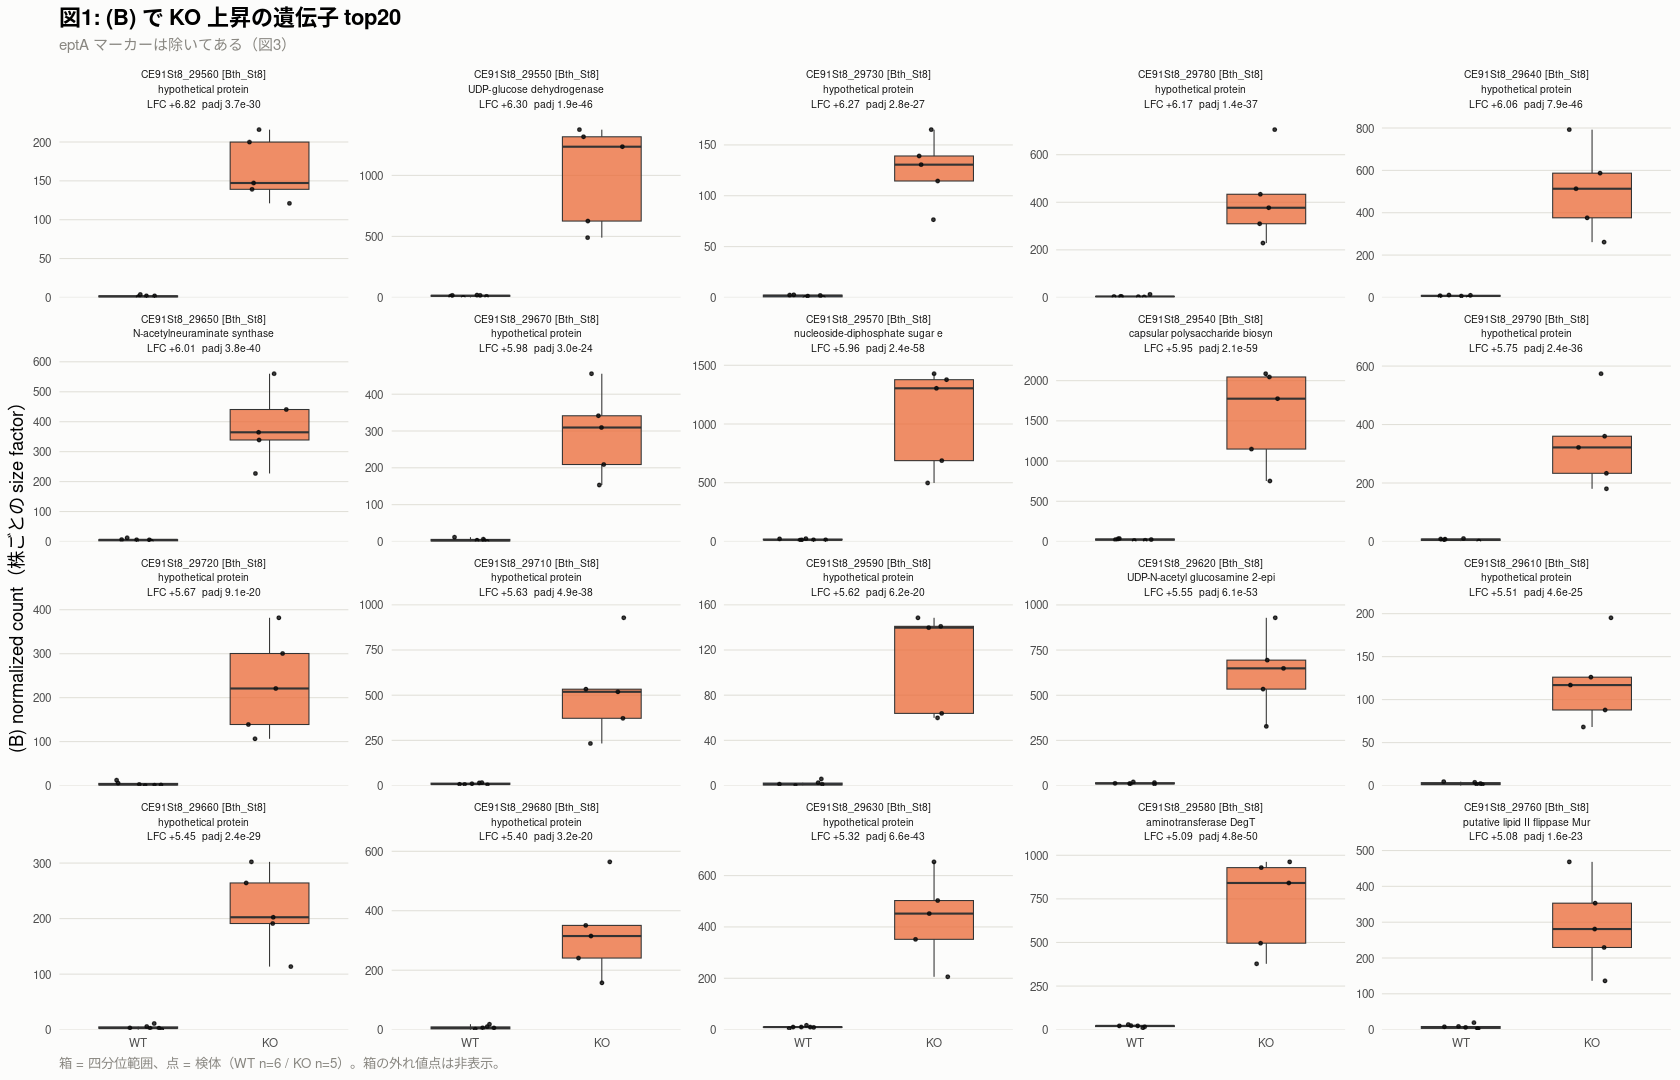

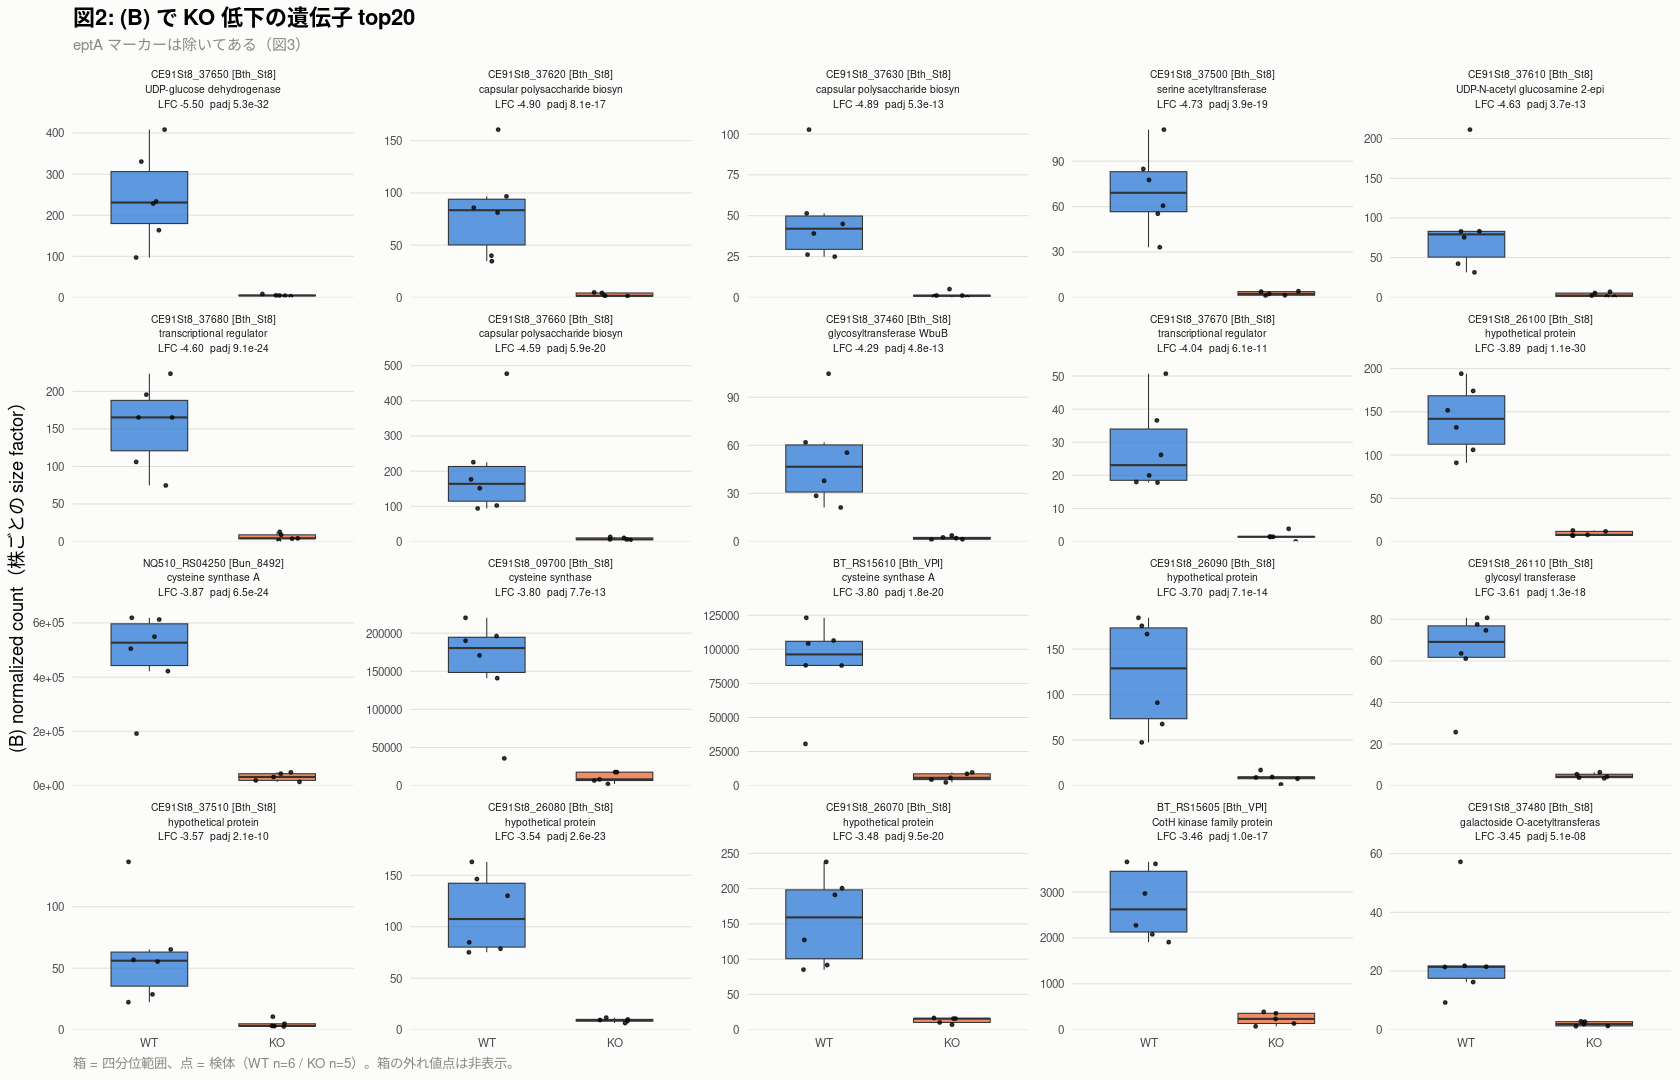

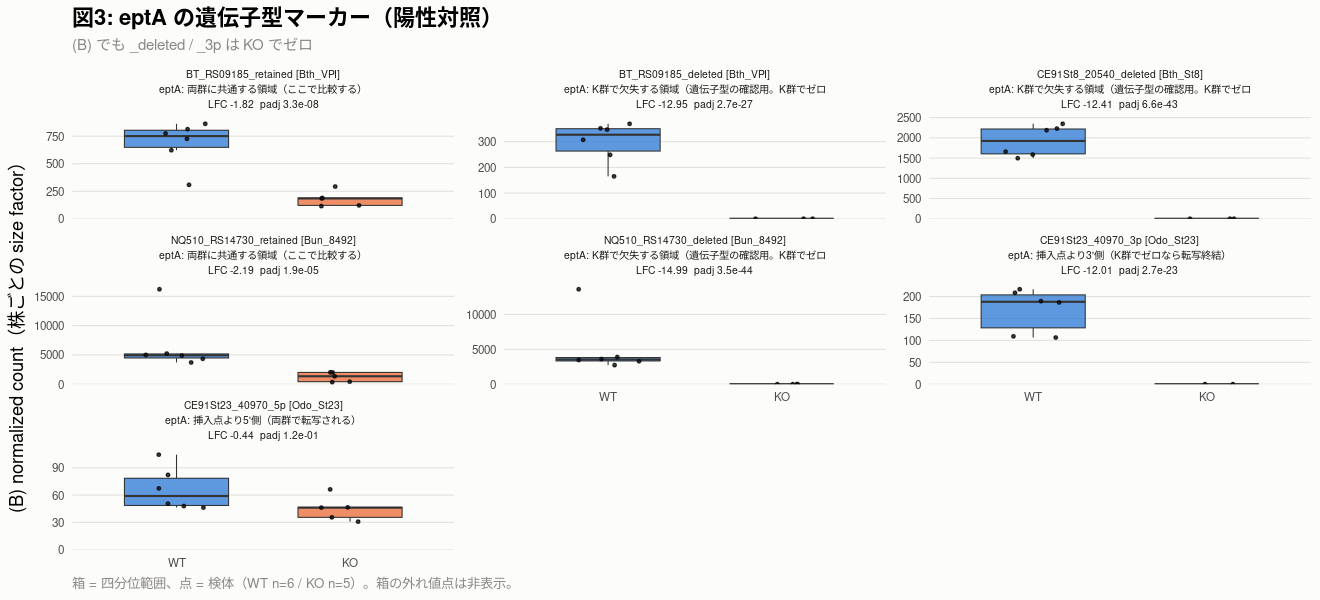

In [27]:
# ── 個別遺伝子の箱ひげ図（(B) 株ごと正規化）────────────────────────
# 5_1 セル14図 と同じ作り。正規化が【株ごと】になっている点だけが違う。
#
# ★ 図4 がこのnotebook 固有。同じ遺伝子を
#   【(A) の正規化】と【(B) の正規化】で並べ、どう見え方が変わるかを示す
library(ggplot2); library(tidyr)

if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}
col_group = c(WT = '#2a78d6', KO = '#eb6834')
thm = theme_minimal(base_size = 11) +
    theme(panel.background = element_rect(fill = col_surface, colour = NA),
          plot.background  = element_rect(fill = col_surface, colour = NA),
          panel.grid.minor = element_blank(), panel.grid.major.x = element_blank(),
          panel.grid.major.y = element_line(colour = col_grid, linewidth = 0.3),
          strip.text = element_text(size = 6.2, lineheight = 1.2),
          axis.text = element_text(size = 7),
          plot.title = element_text(face = 'bold'),
          plot.subtitle = element_text(colour = col_muted, size = 9),
          plot.caption  = element_text(colour = col_muted, size = 8, hjust = 0))

# (B) の正規化カウント（株ごとの size factor で割ったもの）を1つの行列にまとめる
ncB = do.call(rbind, lapply(strains_B, function(s)
    counts(fit_B[[s]]$dds, normalized = TRUE)))
ncB = ncB[de_B$gene_id, ]

normB_long = ncB %>% as.data.frame() %>% tibble::rownames_to_column('gene_id') %>%
    pivot_longer(-gene_id, names_to = 'sample', values_to = 'norm_count') %>%
    mutate(group = factor(coldata$group[match(sample, rownames(coldata))],
                          levels = c('WT','KO')))

lab_B = de_B %>%
    left_join(de_A %>% dplyr::select(gene_id, product), by = 'gene_id') %>%
    mutate(panel = sprintf('%s [%s]\n%s\nLFC %+.2f  padj %s',
                           gene_id, strain, substr(product, 1, 30), LFC_B,
                           format(signif(padj_pooled, 2), scientific = TRUE)))

gene_panels_B = function(ids, ttl, sub, ncol = 5) {
    d = normB_long %>% filter(gene_id %in% ids) %>%
        left_join(lab_B %>% dplyr::select(gene_id, panel), by = 'gene_id') %>%
        mutate(panel = factor(panel, levels = lab_B$panel[match(ids, lab_B$gene_id)]))
    ggplot(d, aes(x = group, y = norm_count, fill = group)) +
        geom_boxplot(outlier.shape = NA, linewidth = 0.3, width = 0.6, alpha = 0.75) +
        geom_jitter(width = 0.18, size = 0.7, alpha = 0.8, colour = col_text) +
        scale_fill_manual(values = col_group) + guides(fill = 'none') +
        scale_y_continuous(limits = c(0, NA), expand = expansion(mult = c(0, 0.08))) +
        facet_wrap(~ panel, ncol = ncol, scales = 'free_y') +
        labs(title = ttl, subtitle = sub, x = NULL,
             y = '(B) normalized count（株ごとの size factor）',
             caption = '箱 = 四分位範囲、点 = 検体（WT n=6 / KO n=5）。箱の外れ値点は非表示。') + thm
}

sigB = de_B %>% left_join(feat_de %>% dplyr::select(gene_id, marker), by='gene_id') %>%
       filter(!is.na(padj_pooled), padj_pooled < 0.05, !marker)
upB   = sigB %>% arrange(desc(LFC_B)) %>% head(20) %>% pull(gene_id)
downB = sigB %>% arrange(LFC_B)       %>% head(20) %>% pull(gene_id)
mkB   = de_B$gene_id[de_B$gene_id %in% feat_de$gene_id[feat_de$marker]]

options(repr.plot.width = 14, repr.plot.height = 9)
suppressWarnings(print(gene_panels_B(upB,
    '図1: (B) で KO 上昇の遺伝子 top20', 'eptA マーカーは除いてある（図3）')))

options(repr.plot.width = 14, repr.plot.height = 9)
suppressWarnings(print(gene_panels_B(downB,
    '図2: (B) で KO 低下の遺伝子 top20', 'eptA マーカーは除いてある（図3）')))

options(repr.plot.width = 11, repr.plot.height = 5)
suppressWarnings(print(gene_panels_B(mkB,
    '図3: eptA の遺伝子型マーカー（陽性対照）',
    '(B) でも _deleted / _3p は KO でゼロ', ncol = 3)))

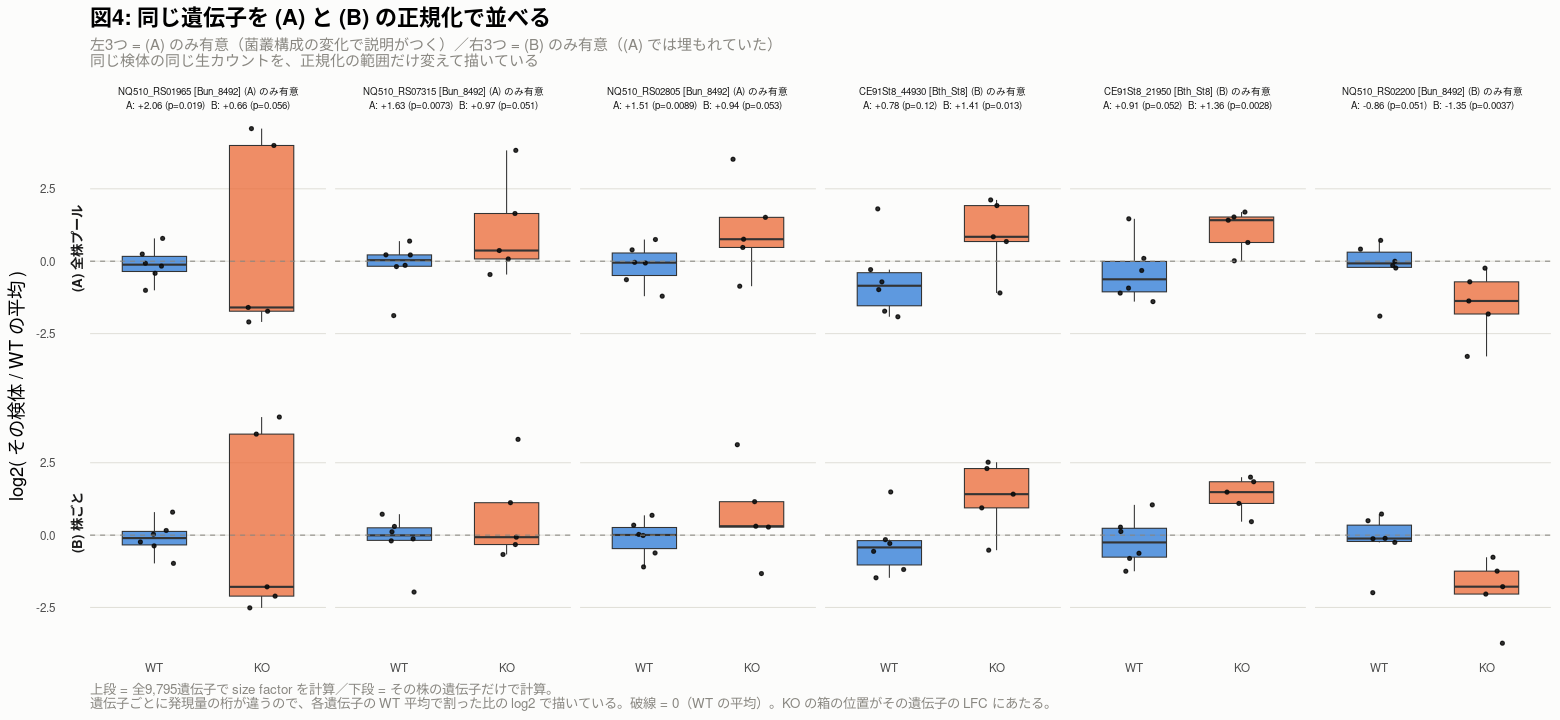

In [28]:
# ── ★ 図4: 同じ遺伝子を (A) の正規化と (B) の正規化で並べる ────────
# セル8 で分類した「(A) のみ有意」「(B) のみ有意」の代表例を取り、
# 同じ検体のカウントを2通りの正規化で描く。
# 正規化の範囲が変わるだけで見え方がどう変わるかを、遺伝子単位で示す
ncA = counts(dds_A, normalized = TRUE)[de_B$gene_id, ]

pick = bind_rows(
    AB %>% filter(分類 == '(A) のみ有意') %>% arrange(desc(abs(LFC_A))) %>%
        filter(!is.na(padj_pooled)) %>% head(3),
    AB %>% filter(分類 == '(B) のみ有意') %>% arrange(desc(abs(LFC_B))) %>%
        filter(!is.na(padj_A)) %>% head(3))

cmp_long = bind_rows(
    ncA[pick$gene_id, ] %>% as.data.frame() %>% tibble::rownames_to_column('gene_id') %>%
        pivot_longer(-gene_id, names_to='sample', values_to='v') %>%
        mutate(正規化 = '(A) 全株プール'),
    ncB[pick$gene_id, ] %>% as.data.frame() %>% tibble::rownames_to_column('gene_id') %>%
        pivot_longer(-gene_id, names_to='sample', values_to='v') %>%
        mutate(正規化 = '(B) 株ごと')) %>%
    mutate(group = factor(coldata$group[match(sample, rownames(coldata))],
                          levels = c('WT','KO')),
           正規化 = factor(正規化, levels = c('(A) 全株プール','(B) 株ごと'))) %>%
    left_join(pick %>% mutate(panel = sprintf('%s [%s] %s\nA: %+.2f (p=%s)  B: %+.2f (p=%s)',
                                              gene_id, strain, 分類,
                                              LFC_A, signif(padj_A, 2),
                                              LFC_B, signif(padj_pooled, 2))) %>%
                  dplyr::select(gene_id, panel), by = 'gene_id') %>%
    mutate(panel = factor(panel, levels = unique(panel))) %>%
    # ★ 遺伝子ごとに発現量の桁が違うので、各遺伝子の【WT 平均】で割った比にする。
    #   こうすると全遺伝子を同じ軸に載せられ、WT が 1 付近、KO が倍率として読める
    group_by(gene_id, 正規化) %>%
    mutate(ratio = log2((v + 1) / mean(v[group == 'WT'] + 1))) %>%
    ungroup()

options(repr.plot.width = 13, repr.plot.height = 6)
p4 = ggplot(cmp_long, aes(x = group, y = ratio, fill = group)) +
    geom_boxplot(outlier.shape = NA, linewidth = 0.3, width = 0.6, alpha = 0.75) +
    geom_jitter(width = 0.18, size = 0.8, alpha = 0.85, colour = col_text) +
    scale_fill_manual(values = col_group) + guides(fill = 'none') +
    geom_hline(yintercept = 0, colour = col_muted, linewidth = 0.3, linetype = 'dashed') +
    facet_grid(正規化 ~ panel, switch = 'y') +
    labs(title = '図4: 同じ遺伝子を (A) と (B) の正規化で並べる',
         subtitle = paste0('左3つ = (A) のみ有意（菌叢構成の変化で説明がつく）／',
                           '右3つ = (B) のみ有意（(A) では埋もれていた）\n',
                           '同じ検体の同じ生カウントを、正規化の範囲だけ変えて描いている'),
         x = NULL, y = 'log2( その検体 / WT の平均 )',
         caption = paste0('上段 = 全9,795遺伝子で size factor を計算／',
                          '下段 = その株の遺伝子だけで計算。\n',
                          '遺伝子ごとに発現量の桁が違うので、各遺伝子の WT 平均で割った比の log2 で描いている。',
                          '破線 = 0（WT の平均）。KO の箱の位置がその遺伝子の LFC にあたる。')) + thm +
    theme(strip.text.x = element_text(size = 5.8, lineheight = 1.2),
          strip.text.y.left = element_text(size = 8, angle = 90, face = 'bold'))
suppressWarnings(print(p4))

### 考察: 個別遺伝子の箱ひげ図（セル9図 の結果）

## 図1・図2 — 上位は (A) と同じ顔ぶれ

**(B) で上昇 top20 も `CE91St8_295xx`〜`297xx`（CPS 座位2）が占める。**
低下 top20 も `CE91St8_374xx`〜`376xx`（座位3）と `CE91St8_260xx`（座位1）。

**CPS 座位の切り替わりは (A) でも (B) でも同じように出る。**
→ **菌叢構成の変化では説明できない、株内の本物の切り替わり**ということ。
これは (B) を回して初めて言えること。

**形も (A) と同じ「オン/オフ」**（WT ≈ 0 → KO で発現）。

## 図3 — 陽性対照は (B) でも機能

4つの `_deleted` / `_3p` が **KO でゼロ**。(A) と同じ。

## ★ 図4 — 正規化の違いが遺伝子単位で見える

### 「(A) のみ有意」の3遺伝子（`Bun_8492`）

上段（(A)）では KO の箱が 0 より明確に上にあるが、
**下段（(B)）では箱が 0 に近づく。**
`Bun_8492` のシェア変化（+0.369 相当）が差し引かれた分だけ下がっている。

**padj は 0.0073〜0.019 → 0.051〜0.056** と、**0.05 のすぐ上**に移る。
**「(A) が偽陽性」でも「(B) が見落とし」でもなく、境界例**だということが図で確認できる。

### 「(B) のみ有意」の3遺伝子

逆に、**上段では箱が 0 に近く、下段で明確に離れる。**
`CE91St8_44930` は **(A) +0.78（p=0.12）→ (B) +1.41（p=0.013）**。
**(A) では `Bth_St8` 全体の動きに埋もれていた**ことになる。

`NQ510_RS02200` は **(A) −0.86（p=0.051）→ (B) −1.35（p=0.0037）** で、
**`Bun_8492` のシェアが上がった分、(A) では低下が過小評価されていた。**

## まとめ

**図4 は「(A) と (B) のどちらが正しいか」ではなく、
「同じ生カウントが、正規化の範囲だけで見え方が変わる」ことを示している。**

- **(A) の問い**（宿主は何にさらされているか）には上段が答える
- **(B) の問い**（各菌が自分の中で何を変えたか）には下段が答える

**どちらも同じデータの別の読み方。** ステージ6 の2パネル図はこれを経路レベルでやる。

## セル10: 感度解析 — `eptAW4` を除いて (B) をやり直す

セル6 で、**`eptAW4` の size factor は株間で 2.30 倍ばらついており**
（`Bth_St8` 1.539 / `Odo_St23` 0.670）、**(A) の1つの係数では表せていなかった。**

**(B) では株ごとに正しい係数が与えられるので、`eptAW4` の影響は (A) より小さいはず。**
それを確かめる。

**※ 株ごとに size factor も dispersion も取り直す**（検体集合が変わるため）。
`results()` だけ取り直すのでは足りない。

### 比較の相手（5_1 セル15 の結果）

|- | (A) |
|---|---|
| DEG | 3,126 → **4,206（+34.5%）** |
| 元の DEG の残存率 | 97.0% |
| 向きが変わった DEG | 0 |

In [29]:
# ── 感度解析: eptAW4 を除いて (B) をやり直す ──────────────────────
# セル6 で、eptAW4 の size factor は株間で 2.30 倍ばらついており
# （Bth_St8 1.539 / Odo_St23 0.670）、(A) の1つの係数では表せていなかった。
# (B) では株ごとに正しい係数が与えられるので、eptAW4 の影響は (A) より小さいはず。
#
# (A) では: DEG 3,126 → 4,206（+35%）、元の DEG の 97.0% が残り、向きの反転 0 件
# それと比べる。
#
# ★ 株ごとに size factor も dispersion も取り直す（検体集合が変わるため）

keep_s = colnames(cnt_de) != 'eptAW4'
fit_Bs = list()
for (s in strains_B) {
    i = feat_de$strain == s
    d = DESeqDataSetFromMatrix(cnt_de[i, keep_s], coldata[keep_s, , drop = FALSE], ~ group)
    d$group = relevel(d$group, ref = 'WT')
    d = estimateSizeFactors(d); d = estimateDispersions(d, quiet = TRUE)
    d = nbinomWaldTest(d, quiet = TRUE)
    fit_Bs[[s]] = list(res = results(d, alpha = 0.05),
                       shr = lfcShrink(d, coef = 'group_KO_vs_WT',
                                       type = 'apeglm', quiet = TRUE))
}

de_Bs = do.call(rbind, lapply(strains_B, function(s) {
    r = fit_Bs[[s]]$res
    data.frame(gene_id = rownames(r), strain = s,
               LFC_Bs = round(fit_Bs[[s]]$shr$log2FoldChange, 4),
               pvalue_Bs = r$pvalue, padj_bystrain_Bs = r$padj, row.names = NULL)
}))
ok = !is.na(de_Bs$padj_bystrain_Bs)
de_Bs$padj_pooled_Bs = NA_real_
de_Bs$padj_pooled_Bs[ok] = p.adjust(de_Bs$pvalue_Bs[ok], method = 'BH')

sens = de_B %>% dplyr::select(gene_id, strain, LFC_B, padj_pooled) %>%
    inner_join(de_Bs %>% dplyr::select(gene_id, LFC_Bs, padj_pooled_Bs), by = 'gene_id') %>%
    mutate(sig_all = !is.na(padj_pooled)    & padj_pooled    < 0.05,
           sig_s   = !is.na(padj_pooled_Bs) & padj_pooled_Bs < 0.05)

cat("■ Table 1: (B) で eptAW4 を除くとどうなるか\n")
both = sens$sig_all & sens$sig_s
data.frame(
    item = c('検定された遺伝子（全11検体）', '検定された遺伝子（eptAW4 除外）',
             'DEG（全11検体）', 'DEG（eptAW4 除外）',
             '元の DEG のうち残るもの', '残存率(%)', '向きが変わった DEG',
             'LFC の相関'),
    value = c(sum(!is.na(sens$padj_pooled)), sum(!is.na(sens$padj_pooled_Bs)),
              sum(sens$sig_all), sum(sens$sig_s), sum(both),
              round(100*sum(both)/sum(sens$sig_all), 1),
              sum(both & sign(sens$LFC_B) != sign(sens$LFC_Bs)),
              round(cor(sens$LFC_B, sens$LFC_Bs, use = 'complete.obs'), 4)),
    check.names = FALSE)

cat("\n■ Table 2: 株ごと\n")
sens %>% group_by(strain) %>%
    summarise(DEG_all = sum(sig_all), DEG_woW4 = sum(sig_s),
              増減 = sum(sig_s) - sum(sig_all),
              `増減率pct` = round(100*(sum(sig_s)-sum(sig_all))/sum(sig_all), 1),
              両方 = sum(sig_all & sig_s),
              LFC相関 = round(cor(LFC_B, LFC_Bs, use='complete.obs'), 4),
              .groups='drop') %>% as.data.frame()

cat("\n■ Table 3: (A) と (B) で eptAW4 の影響を比べる\n")
cat("   (A) の値は 5_1 セル15 の結果\n")
data.frame(
    item = c('DEG（全11検体）', 'DEG（eptAW4 除外）', '増加率(%)',
             '元の DEG の残存率(%)', 'LFC の相関', '向きが変わった DEG'),
    `(A) 全株プール` = c(3126, 4206, round(100*(4206-3126)/3126, 1), 97.0, 0.9655, 0),
    `(B) 株ごと` = c(sum(sens$sig_all), sum(sens$sig_s),
                     round(100*(sum(sens$sig_s)-sum(sens$sig_all))/sum(sens$sig_all), 1),
                     round(100*sum(both)/sum(sens$sig_all), 1),
                     round(cor(sens$LFC_B, sens$LFC_Bs, use='complete.obs'), 4),
                     sum(both & sign(sens$LFC_B) != sign(sens$LFC_Bs))),
    check.names = FALSE)

■ Table 1: (B) で eptAW4 を除くとどうなるか


item,value
<chr>,<dbl>
検定された遺伝子（全11検体）,9645.00
検定された遺伝子（eptAW4 除外）,9771.00
DEG（全11検体）,2964.00
DEG（eptAW4 除外）,3776.00
元の DEG のうち残るもの,2860.00
残存率(%),96.50
向きが変わった DEG,0.00
LFC の相関,0.97



■ Table 2: 株ごと


strain,DEG_all,DEG_woW4,増減,増減率pct,両方,LFC相関
<chr>,<int>,<int>,<int>,<dbl>,<int>,<dbl>
Bth_St8,733,849,116,15.8,708,0.9826
Bth_VPI,598,763,165,27.6,578,0.9682
Bun_8492,1034,1304,270,26.1,998,0.9550
Odo_St23,599,860,261,43.6,576,0.9640



■ Table 3: (A) と (B) で eptAW4 の影響を比べる
   (A) の値は 5_1 セル15 の結果


item,(A) 全株プール,(B) 株ごと
<chr>,<dbl>,<dbl>
DEG（全11検体）,3126.0000,2964.00
DEG（eptAW4 除外）,4206.0000,3776.00
増加率(%),34.5000,27.40
元の DEG の残存率(%),97.0000,96.50
LFC の相関,0.9655,0.97
向きが変わった DEG,0.0000,0.00


### 考察: `eptAW4` を除いた感度解析（セル10 の結果）

## 結論: **(B) でも結論は変わらない。影響は (A) よりやや小さい。**

|- | **(A) 全株プール** | **(B) 株ごと** |
|---|---|---|
| DEG（全11検体） | 3,126 | 2,964 |
| DEG（`eptAW4` 除外） | 4,206 | 3,776 |
| **増加率** | **+34.5%** | **+27.4%** |
| 元の DEG の残存率 | 97.0% | **96.5%** |
| LFC の相関 | 0.9655 | **0.9700** |
| **向きが変わった DEG** | **0** | **0** |

**セル6 の予想どおり (B) の方が影響は小さいが、差は 7 ポイントにとどまる。**

### なぜ (B) でも影響が残るのか

**株ごとの size factor は「正規化のずれ」を直すが、
`eptAW4` が生物学的に他と違うこと自体は直せない。**

`eptAW4` は `Bth_St8` が多く `Odo_St23` が少ないという**構成の偏り**だけでなく、
**各株の中でも発現のばらつきが大きい**（RLE の IQR 1.373）。
後者は株ごとに正規化しても残るので、dispersion を押し上げ続ける。

### 株ごとの影響（`Odo_St23` が最大）

| 株 | 全11検体 | `eptAW4` 除外 | 増減 | **増加率** |
|---|---|---|---|---|
| **Odo_St23** | 599 | **860** | +261 | **+43.6%** |
| Bun_8492 | 1,034 | 1,304 | +270 | +26.1% |
| Bth_VPI | 598 | 763 | +165 | +27.6% |
| **Bth_St8** | 733 | 849 | +116 | **+15.8%** |

**`Odo_St23` が最も影響を受ける。**
`eptAW4` の `Odo_St23` シェアが 2.09% と11検体で最低（他の WT は 2.91〜4.00%）で、
**この株のカウントが最も不安定だった**ため。

**`Bth_St8` が最も影響が小さい**のは、`eptAW4` で `Bth_St8` のシェアが高く
（size factor 1.539）、カウントが安定していたため。

## 方針（(A) と同じ。変更なし）

**`eptAW4` は除外しない。**

- 品質指標は良好（rRNA 除去は11検体で最良）
- **(A) でも (B) でも結論が変わらない**（向きの反転 0 件、残存率 96.5〜97.0%）
- 除くと n=5 vs 5 になり、群内のばらつきの推定がさらに不安定になる

**※ 「DEG が何件あった」を主張に使わない**（(A) と同じ。検体集合に強く依存する）。

## セル11: 結果を保存する

5_1 セル18 と同じ方針。**scratch 側（`DESeq2/`）に全部置き、
小さくて重要なものだけ project 側（`refqc/`）に複製する。**

### `de_B` に統合する列

**ステージ6 が `A_de.csv` と `B_de.csv` の2枚で2パネル図を作れるように**してから保存する。

| 足す列 | 出どころ |
|---|---|
| `product` / `marker` / `biotype` / `mappability` / 座標 / eggNOG のアノテーション | `A_de.csv` |
| `LFC_woW4` / `padj_woW4` | セル10 の感度解析 |
| **`LFC_A` / `padj_A` / `stat_A` / `AvsB`** | **セル8 の (A) vs (B) 比較。4分類を列として持つ** |

**→ 35列。** `B_de.csv` だけで (A) と (B) の両方が引ける。

### ★ `dplyr::any_of()` を使う

`A_de.csv` に列が欠けていても止まらないようにするため。
**5_1 セル18 を実行し直していない場合、座標4列が無いことがある。**

### 保存するもの

| 場所 | ファイル | 内容 |
|---|---|---|
| 両方 | **`B_de.csv` / `stage5B_de.csv`** | **★ 1遺伝子1行の全結果（35列）** |
| 両方 | `B_sizefactors.csv` | 株 × 検体の size factor（セル4） |
| 両方 | `B_AvsB_summary.csv` | (A) vs (B) の4分類（セル8 Table 2） |
| scratch | `B_normalized_counts.csv` | 株ごとに正規化したカウント |
| scratch | `B_all.rds` | 上と `fit_B`（4つの DESeqDataSet）をまとめた list |

In [30]:
# ── 結果を保存する ─────────────────────────────────────────────
# 5_1 セル18 と同じ方針: scratch 側（DESeq2/）に全部置き、
# 小さくて重要なものだけ project 側（refqc/）に複製する。
#
# ★ de_B に (A) の列（product・アノテーション）と感度解析を統合してから保存する。
#   ステージ6 はこの表と A_de.csv の2枚で2パネル図を作れるようにする

de_B_out = de_B %>%
    # ★ any_of を使う。A_de.csv に列が欠けていても止まらないようにするため
    #   （5_1 セル18 を実行し直していない場合に座標列が無いことがある）
    left_join(de_A %>% dplyr::select(gene_id, dplyr::any_of(
                  c('product','marker','biotype','mappability',
                    'contig','strand','start','end',
                    'Preferred_name','KEGG_ko','KEGG_Pathway','COG_category',
                    'PFAMs','EC','CAZy','Description'))),
              by = 'gene_id') %>%
    left_join(de_Bs %>% dplyr::select(gene_id, LFC_woW4 = LFC_Bs,
                                      padj_woW4 = padj_pooled_Bs), by = 'gene_id') %>%
    left_join(AB %>% dplyr::select(gene_id, LFC_A, padj_A, stat_A, 分類),
              by = 'gene_id') %>%
    dplyr::rename(AvsB = 分類)

cat(sprintf("■ de_B_out: %d 行 × %d 列\n", nrow(de_B_out), ncol(de_B_out)))
cat("  ", paste(colnames(de_B_out), collapse = ' / '), "\n")

f = function(x) file.path(path_de, x)
write.csv(de_B_out, f('B_de.csv'), row.names = FALSE)
write.csv(sf_B,     f('B_sizefactors.csv'), row.names = FALSE)
write.csv(ncB,      f('B_normalized_counts.csv'))
write.csv(AB %>% dplyr::count(strain, 分類, name = 'n'),
          f('B_AvsB_summary.csv'), row.names = FALSE)
saveRDS(list(de = de_B_out, fit = fit_B, sizefactors = sf_B,
             normalized = ncB, AvsB = AB), f('B_all.rds'))

to_project = c('B_de.csv'          = 'stage5B_de.csv',
               'B_sizefactors.csv' = 'stage5B_sizefactors.csv',
               'B_AvsB_summary.csv'= 'stage5B_AvsB_summary.csv')
for (i in seq_along(to_project))
    file.copy(f(names(to_project)[i]),
              file.path(path_project, 'refqc', to_project[i]), overwrite = TRUE)

cat("\n■ 保存したもの\n")
rbind(
  data.frame(場所 = 'scratch', ファイル = list.files(path_de, pattern = '^B_'),
             MB = round(file.size(f(list.files(path_de, pattern = '^B_')))/1e6, 2)),
  data.frame(場所 = 'project', ファイル = unname(to_project),
             MB = round(file.size(file.path(path_project, 'refqc',
                                            unname(to_project)))/1e6, 2)))

■ de_B_out: 9785 行 × 35 列
   gene_id / strain / baseMean_B / LFC_B_raw / LFC_B / lfcSE_B / stat_B / pvalue_B / padj_bystrain / normB_WT_mean / normB_KO_mean / normB_diff / padj_pooled / product / marker / biotype / mappability / contig / strand / start / end / Preferred_name / KEGG_ko / KEGG_Pathway / COG_category / PFAMs / EC / CAZy / Description / LFC_woW4 / padj_woW4 / LFC_A / padj_A / stat_A / AvsB 

■ 保存したもの


場所,ファイル,MB
<chr>,<chr>,<dbl>
scratch,B_all.rds,7.82
scratch,B_AvsB_summary.csv,0.00
scratch,B_de.csv,4.14
scratch,B_normalized_counts.csv,1.97
scratch,B_sizefactors.csv,0.00
project,stage5B_de.csv,4.14
project,stage5B_sizefactors.csv,0.00
project,stage5B_AvsB_summary.csv,0.00


### ステージ5-B まとめ

## 結論

**(B) 株ごと独立 DESeq2 は完了。(A) と矛盾せず、両者の差は株ごとのほぼ一定のオフセット。**

| 項目 | 値 |
|---|---|
| 入力 | **9,785 遺伝子**（(A) の 9,795 から pME008 の10を除く）× 11 検体 |
| 検定された遺伝子 | 9,645 |
| **DEG（`padj_pooled` < 0.05）** | **2,964** |
| DEG（`padj_bystrain` < 0.05） | 2,979（両方で 2,920、順位相関 0.9977） |

## (B) で分かったこと

| # | 所見 | 出どころ |
|---|---|---|
| 1 | **dispersion の偏りが解消した。** 傾向線の当てはまりの株間の幅が 25.1 → 2.1 ポイント | セル6 |
| 2 | **`Odo_St23` の dispersion が 30% 下がる**（(A) で最も保守的だった） | セル6 |
| 3 | **株ごとの LFC 中央値が 0 付近にそろう**（株間の幅 0.496 → 0.085） | セル7 |
| 4 | **★ `Bun_8492` の「上昇優勢」が消える**（5.2:1 → 1.15:1） | セル7 |
| 5 | **(A) の DEG の 27.3%（851）が (B) では有意でなくなる。うち 621 が `Bun_8492`** | セル8 |
| 6 | **向きが逆になった遺伝子は4株とも0件** | セル8 |
| 7 | **CPS 座位の切り替わりは (B) でも同じように出る** ＝ 菌叢構成では説明できない株内の現象 | セル9 |
| 8 | **★ 硫黄代謝・レドックス系が (A) と (B) で向きが食い違う可能性** | セル8 |

## ★ 最も重要な所見

**`Bun_8492` が (A) で 1,173 遺伝子の上昇を示していたのは、
菌叢構成の変化（シェア 72.4% → 79.7%）であって、菌1細胞あたりの発現制御ではなかった。**

(B) では 552上昇 / 482低下 とほぼ均衡する。
**過去プロジェクト T19 の PTS の例と同じことが、今回のデータでも起きていた。**

→ **(A) の「群集として `Bun_8492` が何を出しているか」は正しい**（宿主はそれにさらされている）が、
**「`Bun_8492` が発現を上げた」と書いてはいけない。**

## ステージ6 への申し送り

| # | 内容 |
|---|---|
| 1 | **`A_de.csv` と `B_de.csv` の2枚で2パネル図が作れる。** `B_de.csv` には `LFC_A` / `padj_A` / `stat_A` / `AvsB` も入れてある |
| 2 | **スコアは `stat_Wald`（A）と `stat_B`（B）** から `2×(AUC−0.5)` で計算する |
| 3 | **担い手の順位は `norm_diff`（A）と `normB_diff`（B）** = 正味リード増減。遺伝子数ではない |
| 4 | **(B) の padj は `padj_pooled` を使う**（(A) と同じ土俵）。株単位の主張には `padj_bystrain` |
| 5 | **pME008 は (B) に無い**（10遺伝子）。経路解析では (A) のみ |
| 6 | **★ 硫黄代謝・レドックス系を最優先で確認する。** (A) では cysteine synthase が3株で −3.5〜−3.9、(B) では thioredoxin・serine acetyltransferase が上昇 |
| 7 | **CPS 座位は (A)(B) 両方で上位を占める。** 座位をまとめて1事象として扱うか、除いた結果も併せて出す |
| 8 | **compositionality の留保を図の注記に書く**（5_1 セル13） |